Tema 4: Análisis de regresión

* Luisa Merlo García | A01067715
* Edgar Osvaldo Navarro | A01644488
* Ariana Guadalupe Rosales Villalobos | A01644773

Ejercicio 1 (25 puntos)

El conjunto de datos de criminalidad datos de criminalidad de Estados Unidos publicado en el año 1993 consiste de 51 registros para los que se tienen las siguientes variables:


* VR = crímenes violentos por cada 100000 habitantes
* MR = asesinatos por cada 100000 habitantes
* M = porcentaje de áreas metropolitanas
* W = porcentaje de gente blanca
* H = porcentaje de personas con preparatoria terminada
* P = porcentaje con ingresos por debajo del nivel de pobreza
* S = porcentaje de familias con solo un miembro adulto como tutor

Considere como variables predictoras M, W, H, P y S, mientras que VR y MR son variables dependientes. Para este ejercicio, utilizarémos únicamente VR.

Para este conjunto de datos:

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy.stats import shapiro
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("datos/crime_data.csv", encoding="utf-8-sig")
df = df.set_index("State")

predictores = ["M", "W", "H", "P", "S"]
alpha = 0.05

display(df.head())
print("Número de registros:", len(df))
print("Valores faltantes:")
display(df[["VR"] + predictores].isna().sum())

,VR,MR,M,W,H,P,S
State,,,,,,,
AK,761,9.0,41.8,75.2,86.6,9.1,14.3
AL,780,11.6,67.4,73.5,66.9,17.4,11.5
AR,593,10.2,44.7,82.9,66.3,20.0,10.7
AZ,715,8.6,84.7,88.6,78.7,15.4,12.1
CA,1078,13.1,96.7,79.3,76.2,18.2,12.5


Número de registros: 51
Valores faltantes:


VR    0
M     0
W     0
H     0
P     0
S     0
dtype: int64

### 1. Grafique cada variable predictora vs la variable VR.

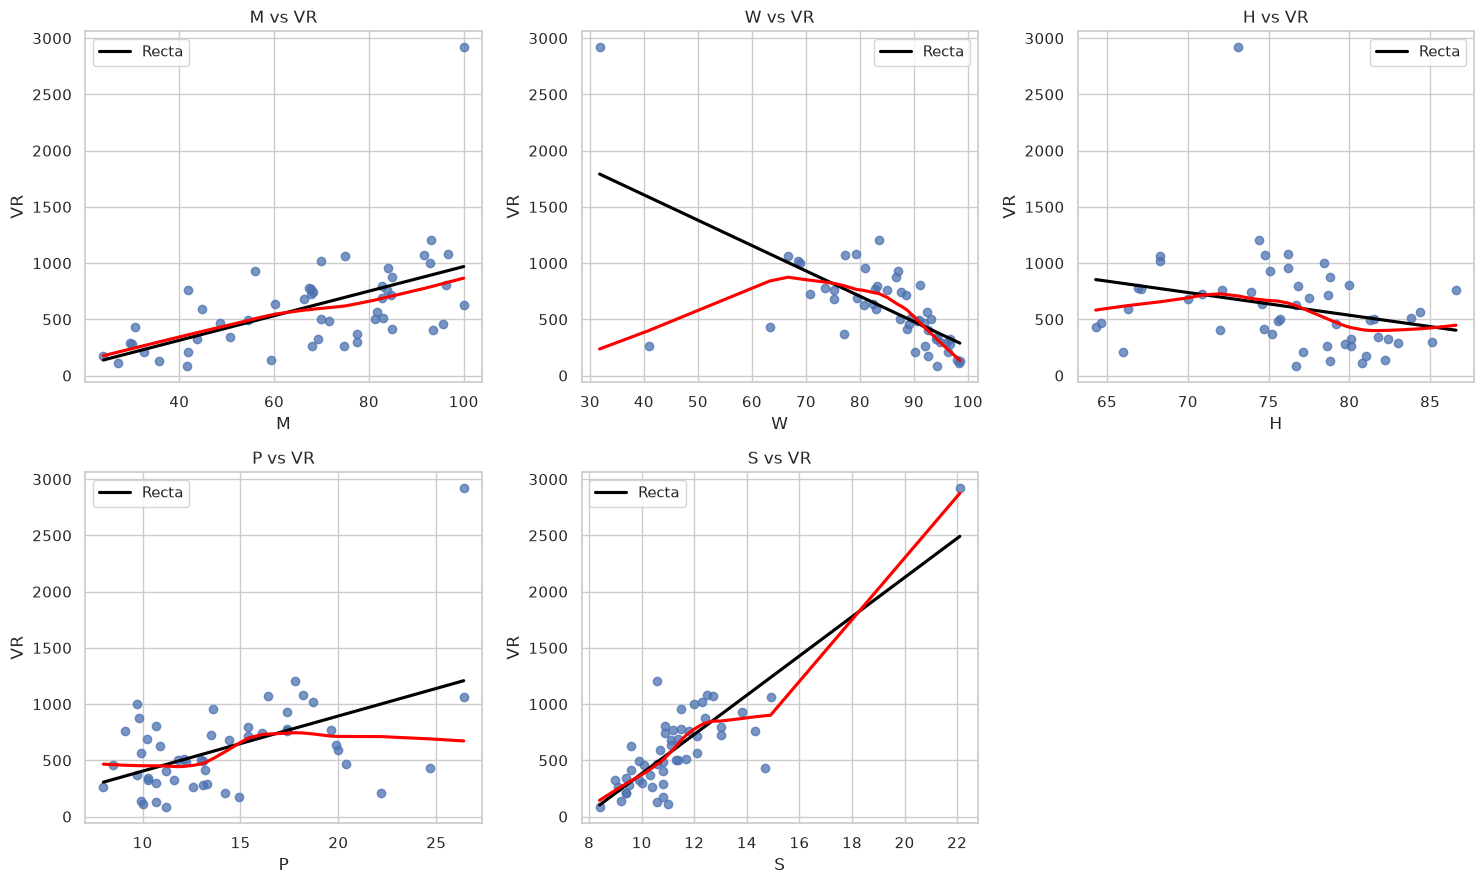

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, variable in zip(axes.flat, predictores):
    sns.regplot(
        data=df, x=variable, y="VR",
        ci=None, ax=ax,
        scatter_kws={"alpha": 0.75},
        line_kws={"color": "black", "label": "Recta"}
    )

    sns.regplot(
        data=df, x=variable, y="VR",
        lowess=True, scatter=False, ax=ax,
        line_kws={"color": "red", "label": "LOWESS"}
    )

    ax.set_title(f"{variable} vs VR")
    ax.legend()

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

Podemos observar que VR tiende a aumentar con M (porcentaje de areas metropolitanas) y S ( porcentaje de familias con solo un miembro adulto como tutor). En  uento a la relacion con H y P muestra bastante dispersion y particularmente W tiende a disminuir..

### 2. Ajuste un modelo de regresión lineal para la variable de respuesta VR con todas las variables predictoras.

In [5]:
X = sm.add_constant(df[predictores])
y = df["VR"]

modelo = sm.OLS(y, X).fit()

print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:                     VR   R-squared:                       0.850
Model:                            OLS   Adj. R-squared:                  0.833
Method:                 Least Squares   F-statistic:                     50.93
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           2.05e-17
Time:                        20:06:14   Log-Likelihood:                -334.06
No. Observations:                  51   AIC:                             680.1
Df Residuals:                      45   BIC:                             691.7
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1795.9045    668.788     -2.685      0.0

Aunque los coeficientes describen asociaciones condcionadas a las demás variabes, no son causales. Observamos en el ajuste de los coeficientes un aumento de un punto porcentual en M se asocia con un aumento estimado de 7.61 en VR. Para S, el aumento estimado es de 109.47. 

### 3. Determine si el modelo pasa la prueba de bondad de ajuste (prueba F), y a su vez determine si los coeficientes pasan su prueba de hipótesis correspondiente (prueba T).

In [6]:
print(f"F global: {modelo.fvalue:.4f}")
print(f"p-valor F: {modelo.f_pvalue:.6g}")

tabla_coeficientes = pd.DataFrame({
    "Coeficiente": modelo.params,
    "Error estándar": modelo.bse,
    "t": modelo.tvalues,
    "p-valor": modelo.pvalues,
    "Significativo al 5%": modelo.pvalues < alpha
})

display(tabla_coeficientes)

F global: 50.9349
p-valor F: 2.04811e-17


,Coeficiente,Error estándar,t,p-valor,Significativo al 5%
const,-1795.904479,668.788462,-2.685310,1.011057e-02,True
M,7.608807,1.295273,5.874290,4.796832e-07,True
W,-4.482908,2.779073,-1.613094,1.137159e-01,False
H,8.646443,7.826015,1.104833,2.751042e-01,False
P,26.244163,11.083273,2.367907,2.224639e-02,True
S,109.466605,20.359892,5.376581,2.601006e-06,True


La prueba F global obtiene F = 50.9349 y p ≈ 2.05 × 10⁻¹⁷. Como p < 0.05, se rechaza la hipótesis de que todos los coeficientes de los predictores sean cero. Por tanto, el modelo es globalmente significativo: existe evidencia de que al menos un predictor está asociado con VR. Aunque esto no garantiza que se cumplan los supuestos del modelo lineal.

En las pruebas t clásicas, M, P y S son significativos al 5 %, mientras que W y H no presentan evidencia suficiente para rechazar que sus coeficientes sean cero, manteniendo constantes los demás predictores.

### 4. Evalúe los valores R2, MSE, RSMSE, MAE.

In [7]:
def metricas_ajuste(ajuste):
    residuos = np.asarray(ajuste.resid)

    return pd.Series({
        "n": int(ajuste.nobs),
        "R2": ajuste.rsquared,
        "R2 ajustado": ajuste.rsquared_adj,
        "MSE": np.mean(residuos**2),
        "RMSE": np.sqrt(np.mean(residuos**2)),
        "MAE": np.mean(np.abs(residuos))
    })

display(metricas_ajuste(modelo).to_frame("Modelo original"))

,Modelo original
n,51.000000
R2,0.849837
R2 ajustado,0.833152
MSE,28644.246122
RMSE,169.246111
MAE,133.419634


El modelo representa aproximadamente el 84.98 % de la variación observada en VR dentro de esta muestra entre las 51 observaciones. Al considerar el número de predictores, el R² ajustado es 83.32 %.
El MAE de 133.42 indica que las estimaciones difieren de los valores observados, en promedio absoluto, en 133.42 crímenes violentos por cada 100000 habitantes. El RMSE de 169.25 penaliza más las diferencias grandes. El MSE es 28644.25, expresado en las unidades de la tasa al cuadrado. 

### 5. Grafique los residuos normalizados del modelo contra los valores ajustados. Genere a su vez el gráfico de cuantil-cuantil para los residuos. ¿Los residuos se comportan tal como se esperaría para un modelo lineal?

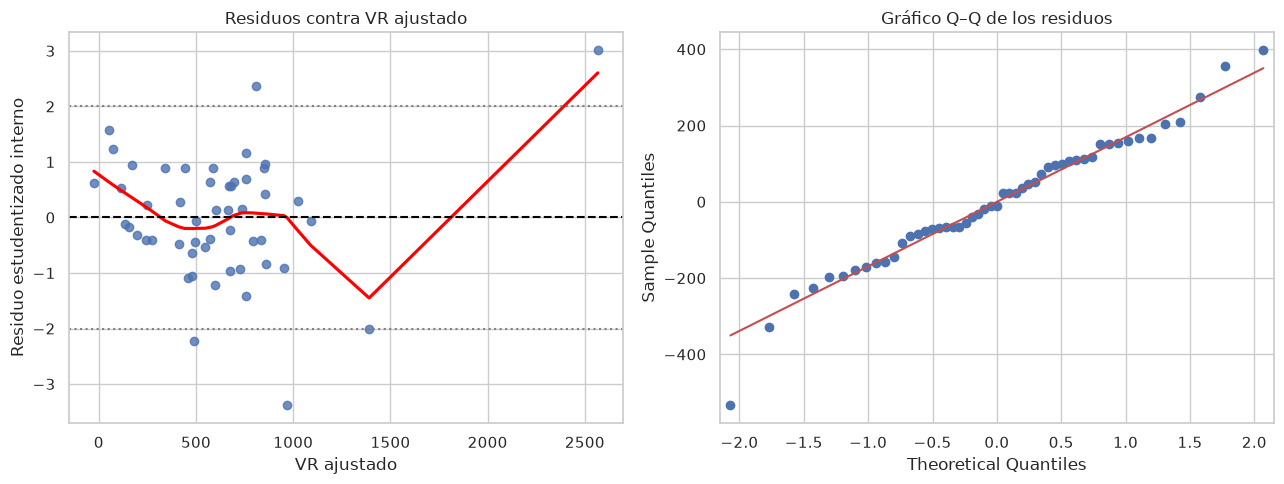

In [8]:
influencia = modelo.get_influence()

residuos_normalizados = influencia.resid_studentized_internal

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.regplot(
    x=modelo.fittedvalues,
    y=residuos_normalizados,
    lowess=True,
    ax=axes[0],
    line_kws={"color": "red"}
)

axes[0].axhline(0, color="black", linestyle="--")
axes[0].axhline(2, color="gray", linestyle=":")
axes[0].axhline(-2, color="gray", linestyle=":")
axes[0].set(
    xlabel="VR ajustado",
    ylabel="Residuo estudentizado interno",
    title="Residuos contra VR ajustado"
)

sm.qqplot(modelo.resid, line="s", ax=axes[1])
axes[1].set_title("Gráfico Q–Q de los residuos")

plt.tight_layout()
plt.show()

No realmente, se observan variaciones extremas y los residuos no forman una dispersion uniforme completamente, presenta una cierta constamcia. La curva roja de lowess también se aparta de cero, aunque sus extremos dependen de pocas observaciones. Por ello, el comportamiento no es completamente compatible con lo esperado para el modelo lineal clásico.

Para los graficos Q–Q, la parte central sigue razonablemente la recta, con desviaciones en las colas. Visualmente, la normalidad parece más plausible que la varianza constante.

### 6. Haga la prueba de normalidad de los residuos, así como la prueba de varianza constante de los residuos. ¿Se obtuvo el resultado esperado en estas pruebas de acuerdo a las gráficas del paso anterior?


In [9]:
def pruebas_diagnostico(ajuste):
    shapiro_stat, shapiro_p = shapiro(ajuste.resid)

    lm, lm_p, f_bp, f_bp_p = het_breuschpagan(
        ajuste.resid,
        ajuste.model.exog,
        robust=True
    )

    return pd.Series({
        "Shapiro estadístico": shapiro_stat,
        "Shapiro p": shapiro_p,
        "BP LM": lm,
        "BP p": lm_p,
        "BP F": f_bp,
        "BP F p": f_bp_p
    })

display(pruebas_diagnostico(modelo).to_frame("Resultado"))

,Resultado
Shapiro estadístico,0.981244
Shapiro p,0.592712
BP LM,15.397403
BP p,0.008793
BP F,3.892318
BP F p,0.005128


Fue lo esperado consderiando lo visto anteriormente, Shapiro–Wilk obtiene p = 0.5927, mayor que 0.05. Por tanto, no se encuentra evidencia suficiente para rechazar la normalidad de los errores en la estimación de los crímenes violentos. Esto coincide con la alineación aproximada del gráfico Q–Q.
Breusch–Pagan obtiene p = 0.0088, menor que 0.05. Por tanto, se rechaza que la variabilidad de los errores sea constante. Las diferencias entre los crímenes violentos observados y estimados no presentan la misma dispersión a lo largo de las combinaciones de predictores. Esto es compatible con la dispersión irregular observada en la gráfica.

### 7.Para el modelo, genere el gráfico de influencia correspondiente. ¿Identificas alguna observación importante que merezca atención? 

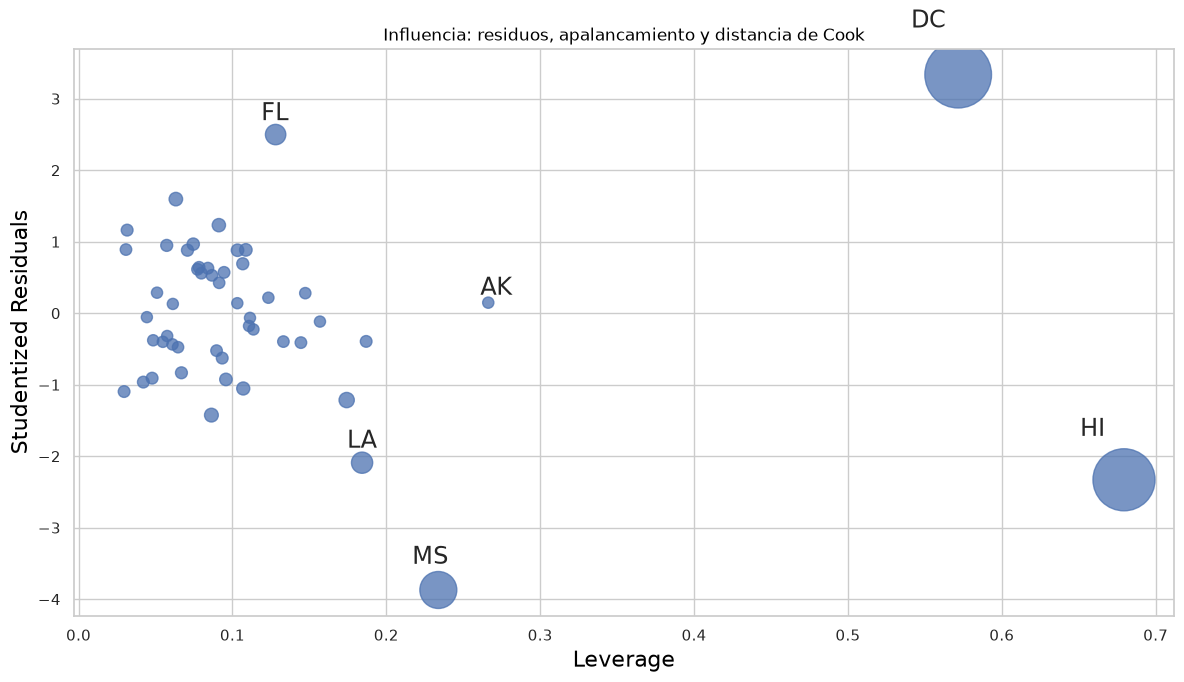

In [10]:
fig, ax = plt.subplots(figsize=(12, 7))

sm.graphics.influence_plot(
    modelo,
    criterion="cooks",
    external=True,
    ax=ax
)

ax.set_title("Influencia: residuos, apalancamiento y distancia de Cook")
plt.tight_layout()
plt.show()

Observamos que DC(Distrito Columbia) y HI (Hawaii) presentan alto apalancamiento con residuos grandes y distancias de Cook elevadas, por lo que tienen una influencia considerable sobre el ajuste de VR. MS presenta el residuo negativo más extremo. En contraste, AK tiene alto apalancamiento, pero un residuo pequeño y poca influencia según Cook. 

El modelo subestima los crímenes violentos del Distrito de Columbia y sobreestima los de Hawái. Misisipi (MS) también destaca porque presenta la mayor diferencia negativa estandarizada: sus crímenes violentos son considerablemente menores que los estimados.

### 8. Identifique gráficamente las observaciones del conjunto de entrenamiento que tengan las siguientes propiedades: 

In [11]:
n, k = X.shape

limites = {
    "Residuos": 2,
    "Apalancamiento": 2 * k / n,
    "Cook": 4 / n,
    "DFFITS": 2 * np.sqrt(k / n),
    "DFBETAS": 2 / np.sqrt(n)
}

diagnosticos = pd.DataFrame({
    "Residuo externo": influencia.resid_studentized_external,
    "Apalancamiento": influencia.hat_matrix_diag,
    "Cook": influencia.cooks_distance[0],
    "DFFITS": influencia.dffits[0]
}, index=df.index)

dfbetas = pd.DataFrame(
    influencia.dfbetas,
    index=df.index,
    columns=X.columns
)

banderas = pd.DataFrame({
    "Residuos":
        diagnosticos["Residuo externo"].abs() > limites["Residuos"],

    "Apalancamiento":
        diagnosticos["Apalancamiento"] > limites["Apalancamiento"],

    "Cook":
        diagnosticos["Cook"] > limites["Cook"],

    "DFFITS":
        diagnosticos["DFFITS"].abs() > limites["DFFITS"],

    "DFBETAS":
        dfbetas.abs().gt(limites["DFBETAS"]).any(axis=1)
})

display(pd.Series(limites, name="Umbral"))

for criterio in banderas.columns:
    print(criterio, ":", df.index[banderas[criterio]].tolist())

display(diagnosticos.loc[banderas.any(axis=1)])

Residuos          2.000000
Apalancamiento    0.235294
Cook              0.078431
DFFITS            0.685994
DFBETAS           0.280056
Name: Umbral, dtype: float64

Residuos : ['FL', 'HI', 'LA', 'MS', 'DC']
Apalancamiento : ['AK', 'HI', 'DC']
Cook : ['FL', 'HI', 'LA', 'MS', 'DC']
DFFITS : ['FL', 'HI', 'LA', 'MS', 'DC']
DFBETAS : ['FL', 'HI', 'LA', 'MS', 'RI', 'WA', 'DC']


,Residuo externo,Apalancamiento,Cook,DFFITS
State,,,,
AK,0.147360,0.266240,0.001342,0.088765
FL,2.498459,0.128049,0.136842,0.957446
HI,-2.329926,0.679388,1.745440,-3.391648
LA,-2.090956,0.184234,0.153095,-0.993681
MS,-3.871252,0.233797,0.581441,-2.138449
RI,-1.214954,0.174224,0.051362,-0.558061
WA,-1.425517,0.086325,0.031282,-0.438171
DC,3.336470,0.571628,2.020803,3.854192


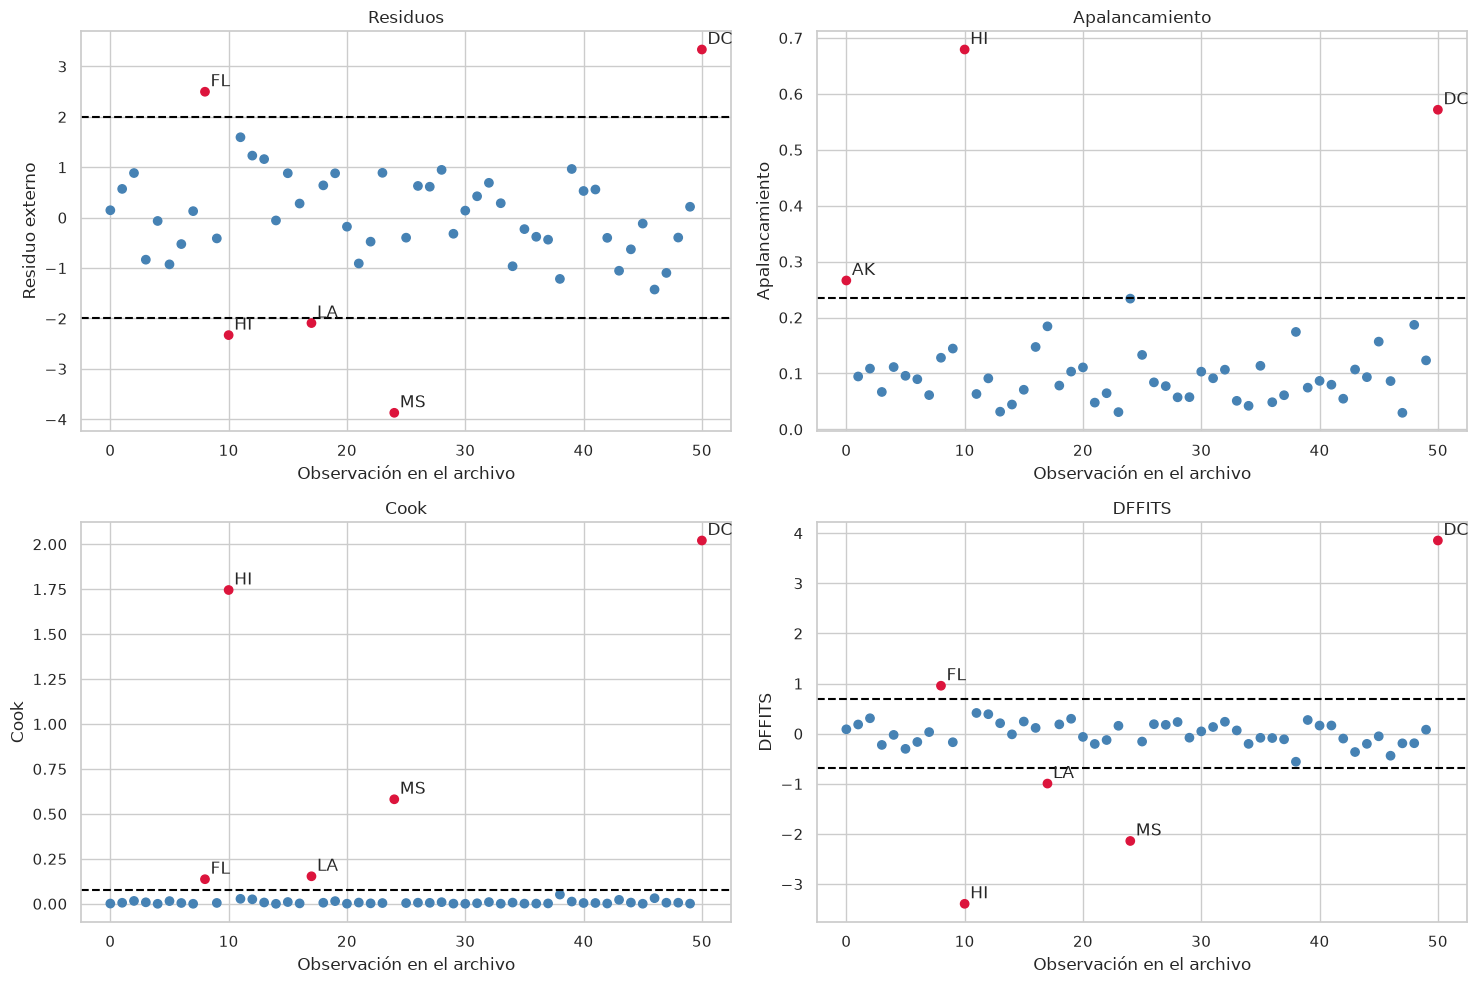

In [13]:
configuracion = [
    ("Residuo externo", "Residuos", True),
    ("Apalancamiento", "Apalancamiento", False),
    ("Cook", "Cook", False),
    ("DFFITS", "DFFITS", True)
]

posiciones = np.arange(n)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, (columna, criterio, bilateral) in zip(
    axes.flat, configuracion
):
    valores = diagnosticos[columna]
    señaladas = banderas[criterio]

    ax.scatter(
        posiciones, valores,
        c=np.where(señaladas, "crimson", "steelblue")
    )

    ax.axhline(limites[criterio], color="black", linestyle="--")

    if bilateral:
        ax.axhline(-limites[criterio], color="black", linestyle="--")

    for j in np.flatnonzero(señaladas.to_numpy()):
        ax.annotate(
            str(df.index[j]),
            (j, valores.iloc[j]),
            xytext=(4, 4),
            textcoords="offset points"
        )

    ax.set(
        title=criterio,
        xlabel="Observación en el archivo",
        ylabel=columna
    )

plt.tight_layout()
plt.show()

En Florida y el Distrito de Columbia, los crímenes violentos por cada 100000 habitantes son mayores que los estimados; en Hawái, Luisiana y Misisipi son menores. Hawái y el Distrito de Columbia destacan por su influencia sobre el ajuste.

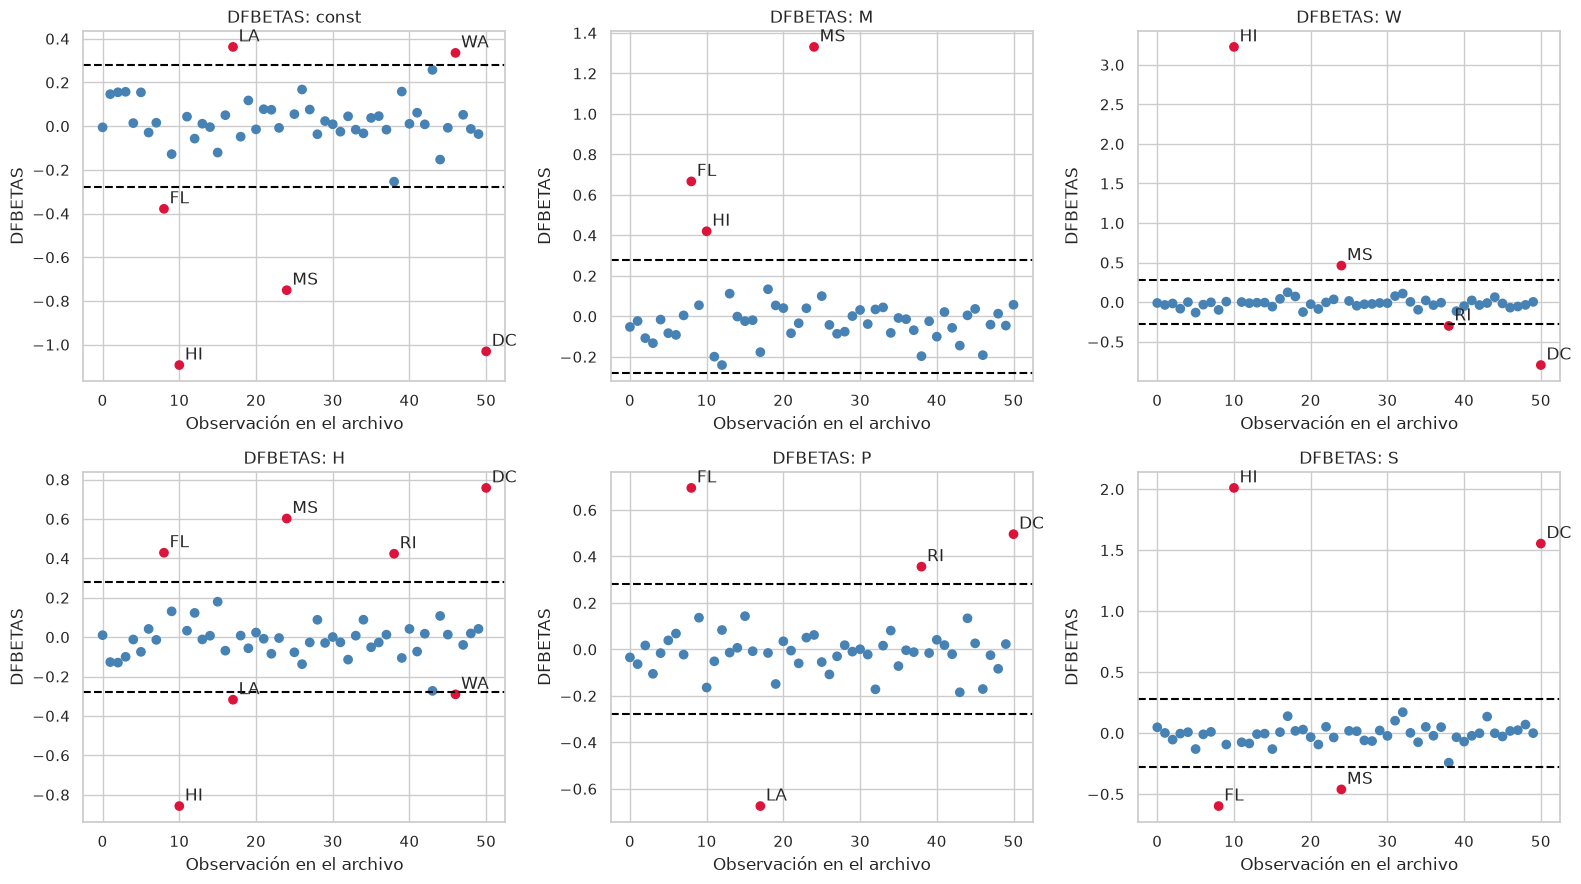

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, termino in zip(axes.flat, dfbetas.columns):
    valores = dfbetas[termino]
    señaladas = valores.abs() > limites["DFBETAS"]

    ax.scatter(
        posiciones, valores,
        c=np.where(señaladas, "crimson", "steelblue")
    )

    ax.axhline(limites["DFBETAS"], color="black", linestyle="--")
    ax.axhline(-limites["DFBETAS"], color="black", linestyle="--")

    for j in np.flatnonzero(señaladas.to_numpy()):
        ax.annotate(
            str(df.index[j]),
            (j, valores.iloc[j]),
            xytext=(4, 4),
            textcoords="offset points"
        )

    ax.set(
        title=f"DFBETAS: {termino}",
        xlabel="Observación en el archivo",
        ylabel="DFBETAS"
    )

plt.tight_layout()
plt.show()

Utilizando DFBETAS que indica de dirección de cambio del coeficiente al retirar la observacipn podemos observar queHawái influye especialmente en las asociaciones estimadas de los crímenes violentos con el porcentaje de gente blanca y el porcentaje de familias con un solo adulto como tutor. Misisipi influye especialmente en la asociación con el porcentaje de áreas metropolitanas. Estas asociaciones son sensibles a incluir o rHetirar dichas observaciones.

### 9. Elimine las observaciones que tengan residuos atípicos, y vuelva a entrenar el modelo con los datos eliminados. Compare los resultados con los obtenidos anteriormente. ¿Se nota alguna mejora?


In [15]:
modelos = {"Original": modelo}

def ajustar_sin(mascara):
    conservar = ~mascara
    return sm.OLS(
        y.loc[conservar],
        X.loc[conservar]
    ).fit()

modelos["Residuos"] = ajustar_sin(banderas["Residuos"])

display(pd.DataFrame({
    nombre: metricas_ajuste(ajuste)
    for nombre, ajuste in modelos.items()
}).T)

print(modelos["Residuos"].summary())
display(pruebas_diagnostico(modelos["Residuos"]))

,n,R2,R2 ajustado,MSE,RMSE,MAE
Original,51.0,0.849837,0.833152,28644.246122,169.246111,133.419634
Residuos,46.0,0.850783,0.832131,11398.651812,106.764469,84.416724


                            OLS Regression Results                            
Dep. Variable:                     VR   R-squared:                       0.851
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     45.61
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.75e-15
Time:                        20:13:38   Log-Likelihood:                -280.12
No. Observations:                  46   AIC:                             572.2
Df Residuals:                      40   BIC:                             583.2
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       -424.0455    504.652     -0.840      0.4

Shapiro estadístico    0.969090
Shapiro p              0.256186
BP LM                  2.319040
BP p                   0.803466
BP F                   0.424723
BP F p                 0.828692
dtype: float64

Al retirar Florida, Hawái, Luisiana, Misisipi y el Distrito de Columbia, el error absoluto promedio al estimar los crímenes violentos por cada 100000 habitantes disminuye de 133.42 a 84.42, y el RMSE baja de 169.25 a 106.76.
R² cambia muy poco, de 84.98 % a 85.08 %, y R² ajustado disminuye ligeramente. La mejora se observa principalmente en los errores y en la varianza de los residuos Breusch–Pagan pasa de p = 0.0088 a 0.8035, por lo que deja de detectarse varianza no constante. Tampoco se rechaza normalidad, con p = 0.2562.

### 10. Repita el paso anterior, pero para el nivel de apalancamiento. Luego haga lo mismo para la distancia de Cook, los valores DFFIT y DFBetas. ¿Con qué método se obtiene un mejor modelo?

In [19]:
for criterio in ["Apalancamiento", "Cook", "DFFITS", "DFBETAS"]:
    modelos[criterio] = ajustar_sin(banderas[criterio])

def resumen_modelo(ajuste):
    resultado = metricas_ajuste(ajuste)
    pruebas = pruebas_diagnostico(ajuste)

    resultado["Shapiro p"] = pruebas["Shapiro p"]
    resultado["BP p"] = pruebas["BP p"]

    return resultado

comparacion = pd.DataFrame({
    nombre: resumen_modelo(ajuste)
    for nombre, ajuste in modelos.items()
}).T

display(comparacion.round(4))

# Comparar  la estabilidad de los coeficientes
coeficientes_comparados = pd.DataFrame({
    nombre: ajuste.params
    for nombre, ajuste in modelos.items()
})

display(coeficientes_comparados.round(4))

,n,R2,R2 ajustado,MSE,RMSE,MAE,Shapiro p,BP p
Original,51.0,0.8498,0.8332,28644.2461,169.2461,133.4196,0.5927,0.0088
Residuos,46.0,0.8508,0.8321,11398.6518,106.7645,84.4167,0.2562,0.8035
Apalancamiento,48.0,0.7548,0.7256,21244.6650,145.7555,117.5246,0.9429,0.3840
Cook,46.0,0.8508,0.8321,11398.6518,106.7645,84.4167,0.2562,0.8035
DFFITS,46.0,0.8508,0.8321,11398.6518,106.7645,84.4167,0.2562,0.8035
DFBETAS,44.0,0.8615,0.8433,10983.3488,104.8015,83.7878,0.4921,0.7619
Todos,43.0,0.8604,0.8415,11189.6558,105.7812,84.7938,0.5928,0.7428


,Original,Residuos,Apalancamiento,Cook,DFFITS,DFBETAS,Todos
const,-1795.9045,-424.0455,-559.4571,-424.0455,-424.0455,-540.1498,-558.8305
M,7.6088,4.9764,7.5342,4.9764,4.9764,5.3852,5.1918
W,-4.4829,-13.0060,-9.1846,-13.0060,-13.0060,-11.6318,-12.0937
H,8.6464,7.5452,7.8259,7.5452,7.5452,6.7471,7.4187
P,26.2442,24.9972,24.8371,24.9972,24.9972,23.8496,23.6299
S,109.4666,78.0099,42.1239,78.0099,78.0099,82.7999,85.0201


La exclusión por DFBETAS obtiene los menores errores de entrenamiento, RMSE = 104.80 y MAE = 83.79 de crimenes violentos. También deja de detectarse falta de normalidad o varianza no constante.
Los criterios de residuos, Cook y DFFITS producen resultados idénticos porque eliminan las mismas observaciones. Excluir únicamente por apalancamiento reduce los errores menos que las otras estrategias.
Por tanto, DFBETAS presenta el mejor ajuste descriptivo sobre las observaciones que conserva. No podemos afirmar que prediga mejor nuevos valores.

### 11. Elimine todas las observaciones que cumpla con alguno de los criterios, y entrene y evalúe el modelo. ¿Se observa alguna mejora? ¿Qué estrategia utilizarías con la información de influencia para mejorar el ajuste de un modelo de regresión lineal?


Observaciones excluidas:
['AK', 'FL', 'HI', 'LA', 'MS', 'RI', 'WA', 'DC']


,n,R2,R2 ajustado,MSE,RMSE,MAE,Shapiro p,BP p
Original,51.0,0.8498,0.8332,28644.2461,169.2461,133.4196,0.5927,0.0088
Residuos,46.0,0.8508,0.8321,11398.6518,106.7645,84.4167,0.2562,0.8035
Apalancamiento,48.0,0.7548,0.7256,21244.6650,145.7555,117.5246,0.9429,0.3840
Cook,46.0,0.8508,0.8321,11398.6518,106.7645,84.4167,0.2562,0.8035
DFFITS,46.0,0.8508,0.8321,11398.6518,106.7645,84.4167,0.2562,0.8035
DFBETAS,44.0,0.8615,0.8433,10983.3488,104.8015,83.7878,0.4921,0.7619
Todos,43.0,0.8604,0.8415,11189.6558,105.7812,84.7938,0.5928,0.7428


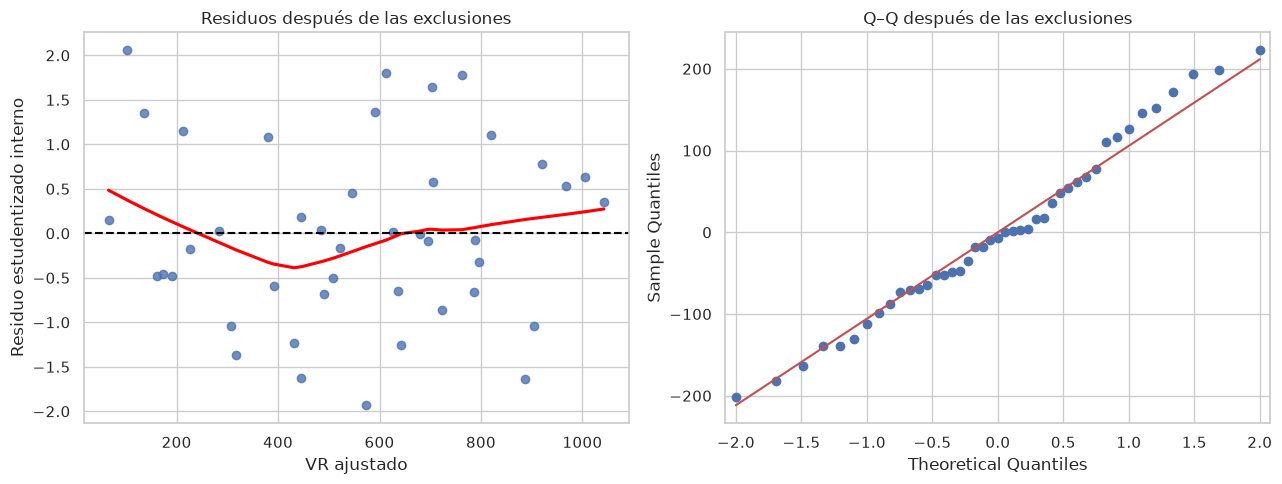

In [17]:
excluir_todas = banderas.any(axis=1)

print("Observaciones excluidas:")
print(df.index[excluir_todas].tolist())

modelos["Todos"] = ajustar_sin(excluir_todas)

comparacion = pd.DataFrame({
    nombre: resumen_modelo(ajuste)
    for nombre, ajuste in modelos.items()
}).T

display(comparacion.round(4))

# Revisar los residuos del ajuste resultante
modelo_todos = modelos["Todos"]
infl_todos = modelo_todos.get_influence()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.regplot(
    x=modelo_todos.fittedvalues,
    y=infl_todos.resid_studentized_internal,
    lowess=True,
    ax=axes[0],
    line_kws={"color": "red"}
)

axes[0].axhline(0, color="black", linestyle="--")
axes[0].set(
    xlabel="VR ajustado",
    ylabel="Residuo estudentizado interno",
    title="Residuos después de las exclusiones"
)

sm.qqplot(modelo_todos.resid, line="s", ax=axes[1])
axes[1].set_title("Q–Q después de las exclusiones")

plt.tight_layout()
plt.show()

Al excluir las ocho observaciones que cumplen al menos un criterio, quedan 43 registros. El MAE disminuye de 133.42 a 84.79 crímenes violentos, y el RMSE baja de 169.25 a 105.78. Sin embargo, los errores son ligeramente mayores que al excluir solamente por DFBETAS: retirar más observaciones no produjo una mejora adicional.
En la imagen, los residuos aparecen más equilibrados alrededor de cero y el Q–Q sigue aproximadamente la recta, aunque hay desviaciones y una ligera curvatura. Esto es compatible con las pruebas: no se rechaza normalidad (p = 0.5928) ni varianza constante (p = 0.7428).


Par ala estrategia utilizaria la información de influencia para revisar las observaciones y comprobar cuánto cambian las asociaciones entre los crímenes violentos y los cinco porcentajes. Solo excluiría registros con una justificación clara; después compararía las alternativas sobre datos de evaluación comunes. La reducción del error en las observaciones conservadas no demuestra, por sí sola, una mejora predictiva general.

### 12. Viendo los resultados de regresión, desarrolle una conclusión indicando que relaciones interesantes encuentras entre la variable de respuesta y los predictores, así como el nivel de influencia de las observaciones.

Como pudimos concluir en los analísis hechos anteriormente se presento que Hawái y el Distrito de Columbia influyen considerablemente en el ajuste. Al excluir las observaciones con residuos atípicos el porcentaje de gente blanca se volvio significativo. Ahora los crímenes violentos por cada 100000 habitantes presentan asociaciones positivas con el porcentaje de áreas metropolitanas y el porcentaje de familias con un solo adulto como tutor, manteniendo constantes los demás predictores. 
En cambio la asociación positiva con el porcentaje de personas por debajo del nivel de pobreza es menos concluyente, pues pierde significancia al utilizar errores estándar robustos. No se encontró evidencia suficiente de una asociación con el porcentaje de personas con preparatoria terminada. 

## Ejercicio 2 (25 puntos)

Repita el ejercicio 1, pero para la variable MR.
Ahora considere el caso multivariado, donde MR y VR son variables dependientes. Repita el ejercicio 1, con los ajustes necesarios para un modelo multivariado.
¿Qué ventaja tiene hacer un modelo multivariado con más de una variable de respuesta?

In [48]:
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

ALPHA = 0.05
PREDICTORAS = ["M", "W", "H", "P", "S"]

# Coloca el CSV en la misma carpeta que el notebook.
df = pd.read_csv("datos/crime_data.csv", encoding="utf-8-sig")
df.columns = df.columns.str.strip()
df["State"] = df["State"].str.strip()
df = df.set_index("State")

columnas = ["VR", "MR"] + PREDICTORAS
df[columnas] = df[columnas].apply(pd.to_numeric, errors="raise")

assert df.index.is_unique, "Hay identificadores de estados duplicados."
assert not df[columnas].isna().any().any(), "Hay valores faltantes."

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (51, 7)


,VR,MR,M,W,H,P,S
State,,,,,,,
AK,761,9.0,41.8,75.2,86.6,9.1,14.3
AL,780,11.6,67.4,73.5,66.9,17.4,11.5
AR,593,10.2,44.7,82.9,66.3,20.0,10.7
AZ,715,8.6,84.7,88.6,78.7,15.4,12.1
CA,1078,13.1,96.7,79.3,76.2,18.2,12.5


In [49]:
def ajustar(datos, respuesta):
    X = sm.add_constant(datos[PREDICTORAS], has_constant="add")
    return sm.OLS(datos[respuesta], X).fit()


def metricas(modelo, datos, respuesta):
    X = sm.add_constant(datos[PREDICTORAS], has_constant="add")
    error = datos[respuesta] - modelo.predict(X)

    return {
        "MSE": np.mean(error**2),
        "RMSE": np.sqrt(np.mean(error**2)),
        "MAE": np.mean(np.abs(error))
    }


def tabla_coeficientes(modelo):
    ic = modelo.conf_int()

    return pd.DataFrame({
        "Coeficiente": modelo.params,
        "Error estándar": modelo.bse,
        "t": modelo.tvalues,
        "p": modelo.pvalues,
        "IC 95% inferior": ic[0],
        "IC 95% superior": ic[1],
        "Significativo al 5%": modelo.pvalues < ALPHA
    })


def pruebas_supuestos(modelo):
    shapiro = stats.shapiro(modelo.resid)

    # Versión de Koenker de Breusch-Pagan, robust=True por defecto.
    bp = het_breuschpagan(
        modelo.resid, modelo.model.exog, robust=True
    )

    reset = linear_reset(
        modelo,
        power=2,
        test_type="fitted",
        use_f=True
    )

    return pd.DataFrame({
        "Prueba": [
            "Shapiro-Wilk",
            "Breusch-Pagan / Koenker",
            "RESET: término cuadrático"
        ],
        "Estadístico": [
            shapiro.statistic,
            bp[0],
            float(reset.fvalue)
        ],
        "p": [
            shapiro.pvalue,
            bp[1],
            float(reset.pvalue)
        ]
    })


### 1. Grafique cada variable predictora vs la variable MR.

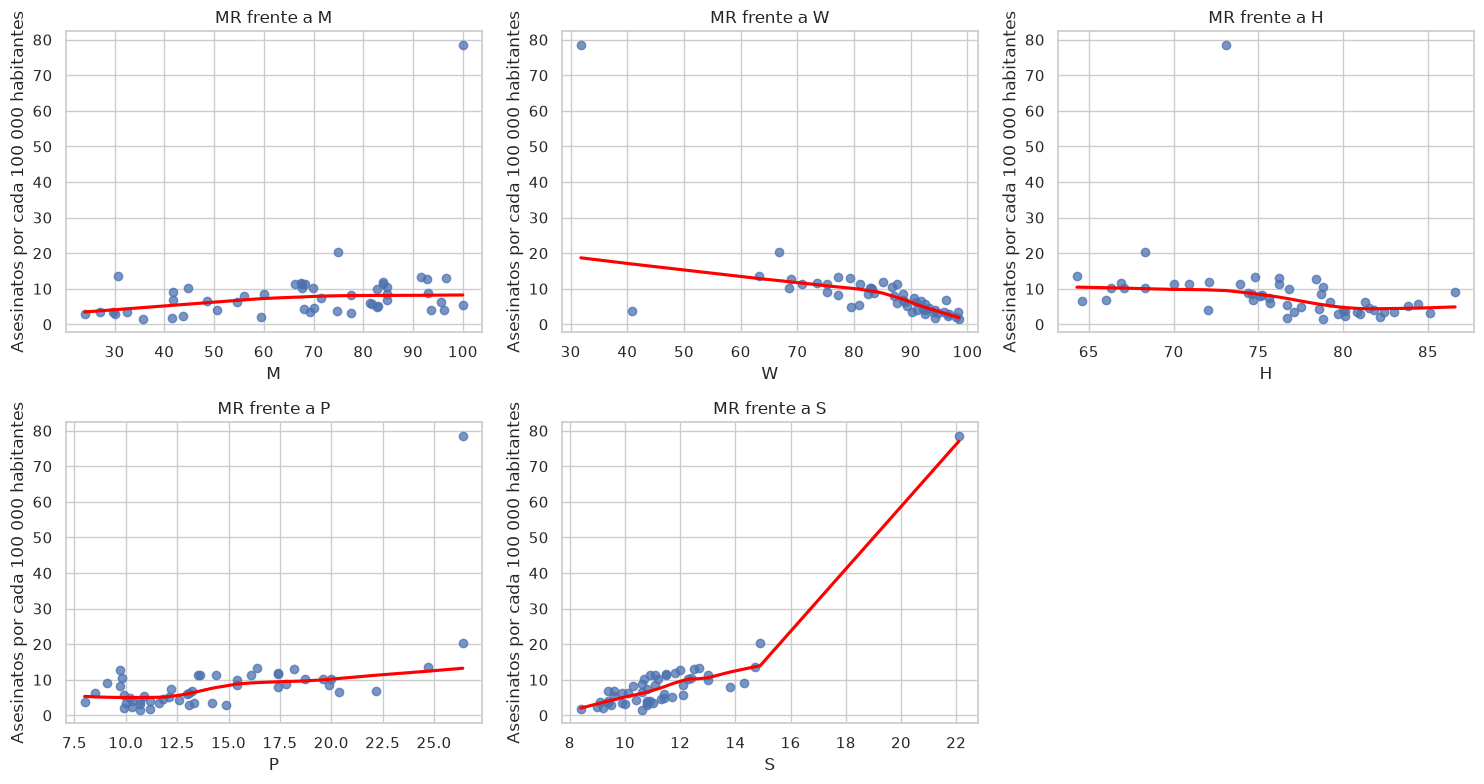

In [50]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, variable in zip(axes.flat, PREDICTORAS):
    sns.regplot(
        data=df,
        x=variable,
        y="MR",
        lowess=True,
        ax=ax,
        scatter_kws={"alpha": 0.75},
        line_kws={"color": "red"}
    )
    ax.set_title(f"MR frente a {variable}")
    ax.set_ylabel("Asesinatos por cada 100 000 habitantes")

axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

Los asesinatos por cada 100000 habitantes (MR), MR muestra una tendencia creciente con M, P y S, y decreciente con W y H,  Destacando especialmente una observación con aproximadamente 78 asesinatos que puede afectar el ajuste.

### 2. Ajuste un modelo de regresión lineal para la variable de respuesta MR con todas las variables predictoras. 

### 3. Determine si el modelo pasa la prueba de bondad de ajuste (prueba F), y a su vez determine si los coeficientes pasan su prueba de hipótesis correspondiente (prueba T).

In [51]:
modelo_mr = ajustar(df, "MR")

print(modelo_mr.summary())

print("\nPrueba F global")
display(pd.DataFrame([{
    "F": modelo_mr.fvalue,
    "p": modelo_mr.f_pvalue,
    "Rechazar H0 al 5%": modelo_mr.f_pvalue < ALPHA
}]))

print("\nPruebas t individuales")
display(tabla_coeficientes(modelo_mr))

                            OLS Regression Results                            
Dep. Variable:                     MR   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     34.97
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           1.98e-14
Time:                        22:01:21   Log-Likelihood:                -152.38
No. Observations:                  51   AIC:                             316.8
Df Residuals:                      45   BIC:                             328.3
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -33.7314     18.972     -1.778      0.0

,F,p,Rechazar H0 al 5%
0,34.968577,1.983664e-14,True



Pruebas t individuales


,Coeficiente,Error estándar,t,p,IC 95% inferior,IC 95% superior,Significativo al 5%
const,-33.731413,18.972152,-1.777943,0.082171,-71.943290,4.480463,False
M,0.051047,0.036744,1.389256,0.171591,-0.022960,0.125054,False
W,-0.195887,0.078837,-2.484722,0.016751,-0.354672,-0.037102,True
H,0.199590,0.222008,0.899020,0.373428,-0.247557,0.646736,False
P,0.581403,0.314410,1.849189,0.071006,-0.051851,1.214657,False
S,2.824680,0.577568,4.890642,0.000013,1.661398,3.987962,True


Los coeficientes representan asociaciones con la tasa de asesinatos manteniendo constantes los demás predictores.

Mientras que en la prueba F  F = 34.97 y p ≈ 1.98 × 10⁻¹⁴, por lo que se rechaza que todas las pendientes sean cero: el modelo es globalmente significativo. En las pruebas t clásicas, únicamente W y S son significativos al 5 %, con asociaciones negativa y positiva con MR.

## 4.Evalúe los valores R2, MSE, RSMSE, MAE.

In [52]:
evaluacion_mr = {
    "n": int(modelo_mr.nobs),
    "R²": modelo_mr.rsquared,
    "R² ajustado": modelo_mr.rsquared_adj,
    **metricas(modelo_mr, df, "MR")
}

display(pd.DataFrame([evaluacion_mr]).round(6))

,n,R²,R² ajustado,MSE,RMSE,MAE
0,51,0.795308,0.772565,23.051175,4.801164,3.404793


### 5. Grafique los residuos normalizados del modelo contra los valores ajustados. Genere a su vez el gráfico de cuantil-cuantil para los residuos. ¿Los residuos se comportan tal como se esperaría para un modelo lineal?


### 6. Haga la prueba de normalidad de los residuos, así como la prueba de varianza constante de los residuos. ¿Se obtuvo el resultado esperado en estas pruebas de acuerdo a las gráficas del paso anterior?

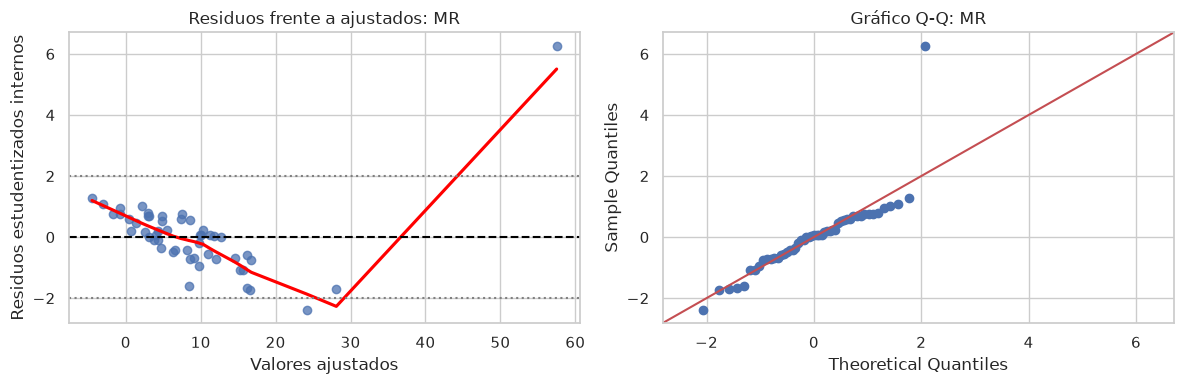

,Prueba,Estadístico,p
0,Shapiro-Wilk,0.894869,2.847629e-04
1,Breusch-Pagan / Koenker,35.540385,1.173612e-06
2,RESET: término cuadrático,217.198138,1.254664e-18


In [53]:
def graficas_residuos(modelo, nombre):
    influencia = modelo.get_influence()
    residuos = influencia.resid_studentized_internal

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.regplot(
        x=modelo.fittedvalues,
        y=residuos,
        lowess=True,
        ax=axes[0],
        line_kws={"color": "red"},
        scatter_kws={"alpha": 0.75}
    )

    axes[0].axhline(0, color="black", linestyle="--")
    axes[0].axhline(2, color="gray", linestyle=":")
    axes[0].axhline(-2, color="gray", linestyle=":")
    axes[0].set_xlabel("Valores ajustados")
    axes[0].set_ylabel("Residuos estudentizados internos")
    axes[0].set_title(f"Residuos frente a ajustados: {nombre}")

    sm.qqplot(residuos, line="45", ax=axes[1])
    axes[1].set_title(f"Gráfico Q-Q: {nombre}")

    plt.tight_layout()
    plt.show()


graficas_residuos(modelo_mr, "MR")
display(pruebas_supuestos(modelo_mr))

Los residuos presentan un patrón marcado respecto a los valores ajustados, en lugar de dispersarse aleatoriamente alrededor de cero. Además, aparece un residuo positivo extremo y una desviación importante en la cola superior del gráfico Q-Q. Esto sugiere problemas en la forma funcional y en la normalidad de los errores, así como posible varianza no constante.

Los tres resultados señalan problemas en el ajuste inicial  por lo que se rechazan la normalidad y la varianza constante de los errores al 5 %. RESET también resulta significativo, con p ≈ 1.25 × 10⁻¹. Por tanto, las pruebas F y t clásicas deben interpretarse con cuidado.

### 7. Para el modelo, genere el gráfico de influencia correspondiente. ¿Identificas alguna observación importante que merezca atención?

DE manaera destacable el Distrito de Columbia (DC) destaca por combinar alto apalancamiento, un residuo positivo extremo y elevada distancia de Cook: su tasa de asesinatos es mucho mayor que la estimada. Hawái (HI) también presenta alto apalancamiento, mientras que Misisipi tiene una tasa de asesinatos menor que la prevista.

### 8. Identifique gráficamente las observaciones del conjunto de entrenamiento que tengan las siguientes propiedades:

    Valores atípicos de residuos
    Valores altos de apalancamiento
    Valores altos de distancia de Cook
    Valores altos de DFFIT
    Valores altos de DFBetas



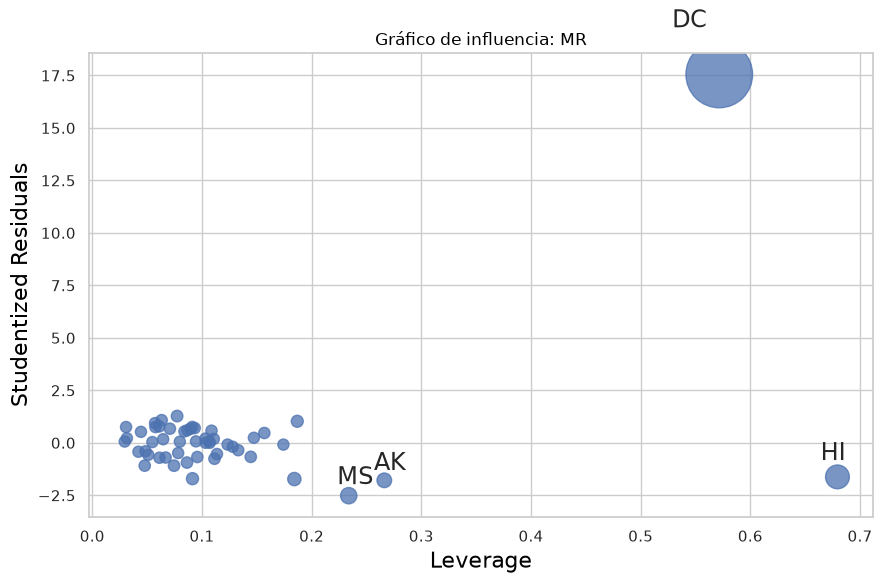

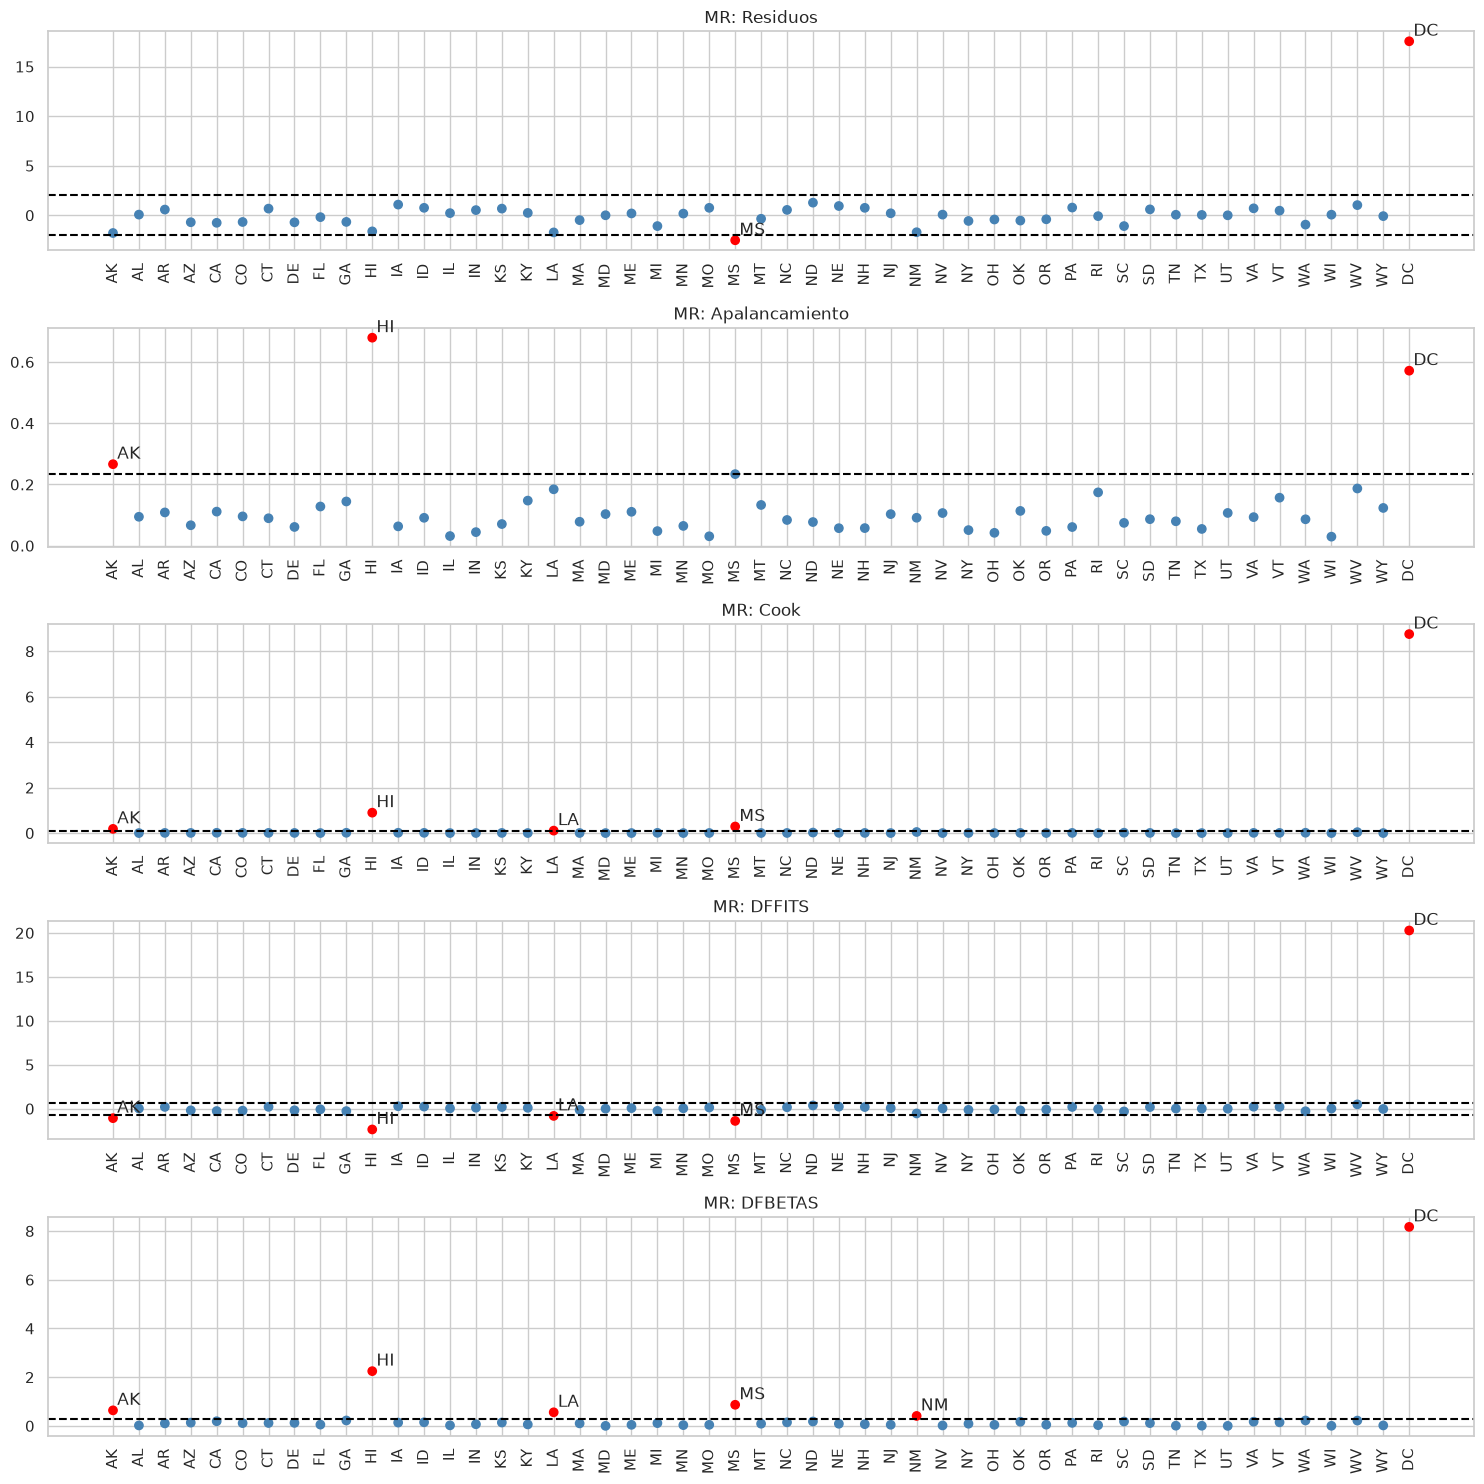

Residuos : ['MS', 'DC']
Apalancamiento : ['AK', 'HI', 'DC']
Cook : ['AK', 'HI', 'LA', 'MS', 'DC']
DFFITS : ['AK', 'HI', 'LA', 'MS', 'DC']
DFBETAS : ['AK', 'HI', 'LA', 'MS', 'NM', 'DC']
Cualquiera : ['AK', 'HI', 'LA', 'MS', 'NM', 'DC']


In [56]:
def diagnostico_influencia(modelo):
    infl = modelo.get_influence()
    indice = modelo.model.data.row_labels
    n, p = modelo.model.exog.shape

    valores = pd.DataFrame({
        "Residuos": infl.resid_studentized_external,
        "Apalancamiento": infl.hat_matrix_diag,
        "Cook": infl.cooks_distance[0],
        "DFFITS": infl.dffits[0]
    }, index=indice)

    dfbetas = pd.DataFrame(
        infl.dfbetas,
        index=indice,
        columns=modelo.model.exog_names
    )

    umbrales = {
        "Residuos": 2,
        "Apalancamiento": 2*p/n,
        "Cook": 4/n,
        "DFFITS": 2*np.sqrt(p/n),
        "DFBETAS": 2/np.sqrt(n)
    }

    valores["DFBETAS"] = dfbetas.abs().max(axis=1)

    banderas = pd.DataFrame(index=indice)

    for criterio in umbrales:
        banderas[criterio] = (
            valores[criterio].abs() > umbrales[criterio]
        )

    banderas["Cualquiera"] = banderas.any(axis=1)

    return valores, dfbetas, banderas, umbrales


def graficar_diagnosticos(modelo, nombre):
    valores, dfbetas, banderas, umbrales = (
        diagnostico_influencia(modelo)
    )

    fig, ax = plt.subplots(figsize=(9, 6))
    sm.graphics.influence_plot(
        modelo, external=True, criterion="cooks", ax=ax
    )
    ax.set_title(f"Gráfico de influencia: {nombre}")
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(5, 1, figsize=(15, 15))
    posiciones = np.arange(len(valores))

    for ax, criterio in zip(axes, umbrales):
        y = valores[criterio]
        colores = np.where(banderas[criterio], "red", "steelblue")

        ax.scatter(posiciones, y, c=colores)
        ax.axhline(
            umbrales[criterio], color="black", linestyle="--"
        )

        if criterio in ["Residuos", "DFFITS"]:
            ax.axhline(
                -umbrales[criterio],
                color="black",
                linestyle="--"
            )

        for posicion in np.flatnonzero(banderas[criterio]):
            ax.annotate(
                str(valores.index[posicion]),
                (posicion, y.iloc[posicion]),
                xytext=(3, 4),
                textcoords="offset points"
            )

        ax.set_title(f"{nombre}: {criterio}")
        ax.set_xticks(posiciones)
        ax.set_xticklabels(valores.index, rotation=90)

    plt.tight_layout()
    plt.show()

    for criterio in banderas:
        print(
            criterio,
            ":",
            banderas.index[banderas[criterio]].tolist()
        )

    return valores, dfbetas, banderas


valores_mr, dfbetas_mr, banderas_mr = graficar_diagnosticos(
    modelo_mr, "MR"
)

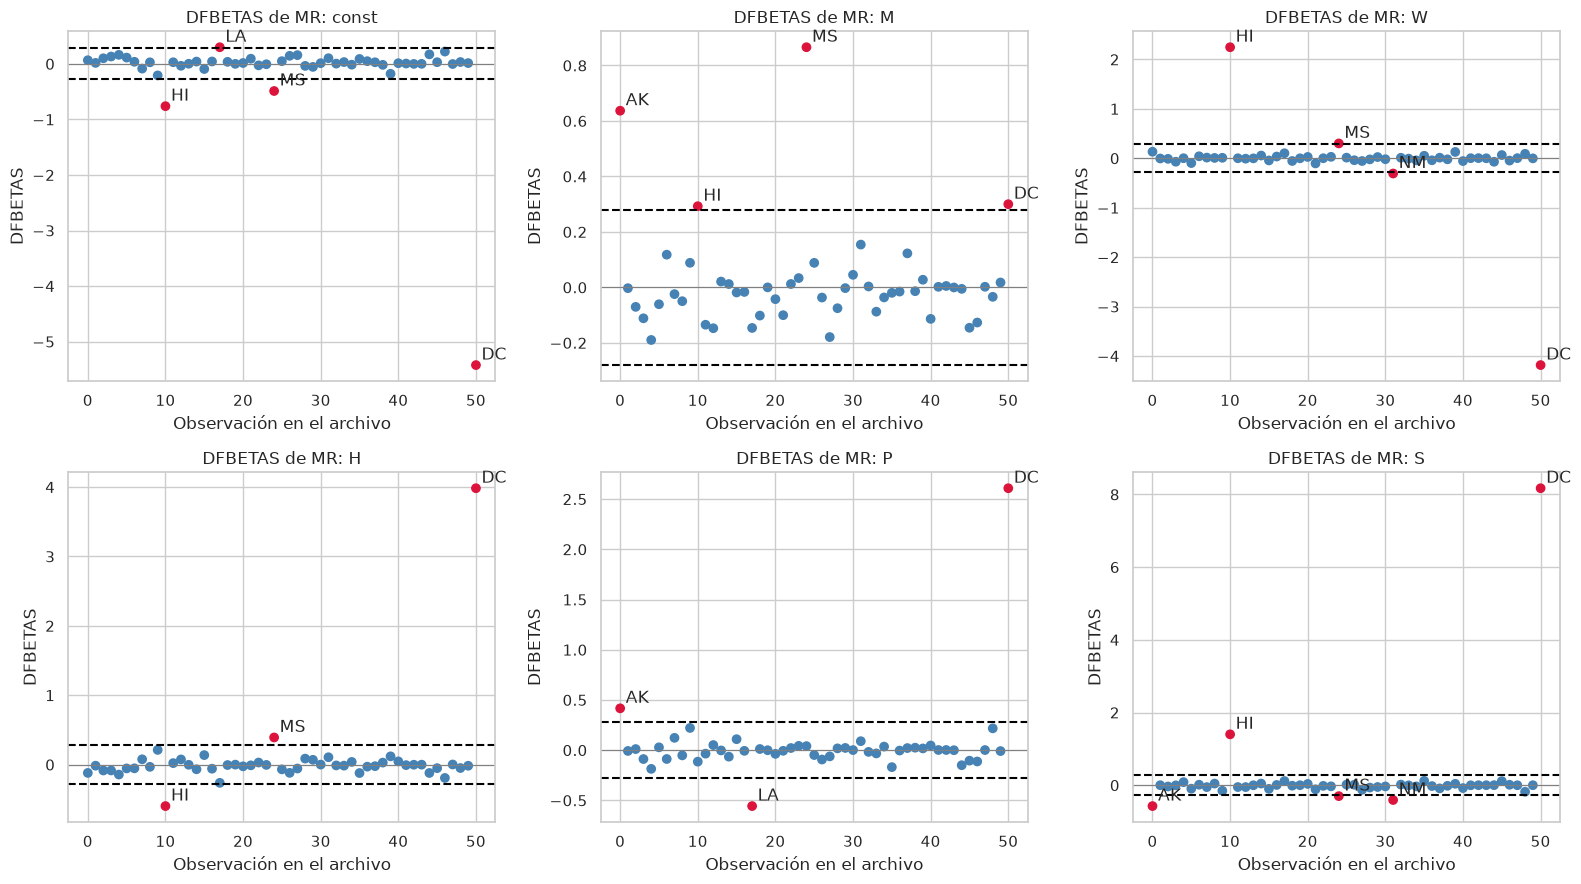

In [57]:
umbral = 2 / np.sqrt(int(modelo_mr.nobs))
posiciones = np.arange(len(dfbetas_mr))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, termino in zip(axes.flat, dfbetas_mr.columns):
    valores = dfbetas_mr[termino]
    senaladas = valores.abs() > umbral

    ax.scatter(
        posiciones,
        valores,
        c=np.where(senaladas, "crimson", "steelblue")
    )

    ax.axhline(umbral, color="black", linestyle="--")
    ax.axhline(-umbral, color="black", linestyle="--")
    ax.axhline(0, color="gray", linewidth=0.8)

    for j in np.flatnonzero(senaladas.to_numpy()):
        ax.annotate(
            str(dfbetas_mr.index[j]),
            (j, valores.iloc[j]),
            xytext=(4, 4),
            textcoords="offset points"
        )

    ax.set(
        title=f"DFBETAS de MR: {termino}",
        xlabel="Observación en el archivo",
        ylabel="DFBETAS"
    )

plt.tight_layout()
plt.show()


Se identifico que los residuos atípicos corresponden a Misisipi y el Distrito de Columbia. Alaska, Hawái y el Distrito de Columbia presentan combinaciones inusuales de las características demográficas y socioeconómicas utilizadas como predictores, por lo que tienen alto apalancamiento. DFBETAS también identifica a Nuevo México. El Distrito de Columbia influye especialmente en el coeficiente del porcentaje de familias con un solo adulto como tutor. 

### 9. Elimine las observaciones que tengan residuos atípicos, y vuelva a entrenar el modelo con los datos eliminados. Compare los resultados con los obtenidos anteriormente. ¿Se nota alguna mejora?

Si, al retirar Misisipi y el Distrito de Columbia, el RMSE de entrenamiento disminuye de 4.80 a 1.68 y el MAE de 3.40 a 1.38 asesinatos por cada 100000 habitantes. Además, dejan de rechazarse la normalidad, la varianza constante y la especificación evaluada por RESET al 5 %. Sin embargo, al evaluar nuevamente los 51 registros, el RMSE aumenta a 6.89. La mejora corresponde al conjunto conservado y no es uniforme sobre los datos originales. El coeficiente del porcentaje de familias con un solo adulto como tutor baja de 2.82 a 1.22,

### 10. Repita el paso anterior, pero para el nivel de apalancamiento. Luego haga lo mismo para la distancia de Cook, los valores DFFIT y DFBetas. ¿Con qué método se obtiene un mejor modelo?

La eliminación por DFBETAS obtiene el menor RMSE de entrenamiento, de 1.5. Cook y DFFITS producen resultados iguales y el menor MAE, de 1.22. La eliminación por apalancamiento obtiene el mayor R² ajustado, de 0.8232.

Por ello, no existe un ganador independiente del criterio utilizado. DFBETAS destaca por su RMSE sobre las observaciones conservadas, pero todos los modelos reducidos aumentan el RMSE al evaluarse sobre los 51 registros originales. No puede afirmarse que predigan mejor datos nuevos.

### 11. Elimine todas las observaciones que cumpla con alguno de los criterios, y entrene y evalúe el modelo. ¿Se observa alguna mejora? ¿Qué estrategia utilizarías con la información de influencia para mejorar el ajuste de un modelo de regresión lineal?


Al eliminar todas las observaciones señaladas, quedan 45 registros y se obtiene exactamente el mismo modelo que con DFBETAS. El RMSE de entrenamiento disminuye de 4.80 a 1.51 de MR y no se rechazan los supuestos evaluados al 5 %. Sin embargo, el RMSE sobre los registros originales aumenta a 6.86.

Se podrían utilizar los diagnósticos de los modelos y sus desempeños para verificar los registros y estudiar la estabilidad de las asociaciones antes de eliminar observaciones válidas. 


In [55]:
def comparar_eliminaciones(datos, respuesta, banderas):
    modelos = {}
    filas = []
    coeficientes = {}

    escenarios = {
        "Original": pd.Series(False, index=datos.index),
        **{nombre: banderas[nombre] for nombre in banderas}
    }

    for nombre, eliminar in escenarios.items():
        entrenamiento = datos.loc[~eliminar]
        modelo = ajustar(entrenamiento, respuesta)

        modelos[nombre] = modelo
        coeficientes[nombre] = modelo.params

        errores_ajuste = metricas(
            modelo, entrenamiento, respuesta
        )
        errores_comunes = metricas(
            modelo, datos, respuesta
        )

        filas.append({
            "Modelo": nombre,
            "n": len(entrenamiento),
            "Eliminados": ", ".join(datos.index[eliminar]),
            "R² entrenamiento": modelo.rsquared,
            "R² ajustado": modelo.rsquared_adj,
            **{
                f"{k} entrenamiento": v
                for k, v in errores_ajuste.items()
            },
            **{
                f"{k} referencia original": v
                for k, v in errores_comunes.items()
            }
        })

    return (
        pd.DataFrame(filas).set_index("Modelo"),
        modelos,
        pd.DataFrame(coeficientes).T
    )


comparacion_mr, modelos_mr, coeficientes_mr = (
    comparar_eliminaciones(df, "MR", banderas_mr)
)

display(comparacion_mr.round(4))
display(coeficientes_mr.round(4))

# Revisar si la eliminación también cambia los diagnósticos.
for nombre, modelo in modelos_mr.items():
    print("\nModelo:", nombre)
    display(pruebas_supuestos(modelo))

,n,Eliminados,R² entrenamiento,R² ajustado,MSE entrenamiento,RMSE entrenamiento,MAE entrenamiento,MSE referencia original,RMSE referencia original,MAE referencia original
Modelo,,,,,,,,,,
Original,51,,0.7953,0.7726,23.0512,4.8012,3.4048,23.0512,4.8012,3.4048
Residuos,49,"MS, DC",0.8122,0.7904,2.8318,1.6828,1.3830,47.4817,6.8907,2.3304
Apalancamiento,48,"AK, HI, DC",0.8420,0.8232,2.5093,1.5841,1.2870,50.0558,7.0750,2.3487
Cook,46,"AK, HI, LA, MS, DC",0.8075,0.7835,2.3005,1.5167,1.2213,49.3231,7.0230,2.3430
DFFITS,46,"AK, HI, LA, MS, DC",0.8075,0.7835,2.3005,1.5167,1.2213,49.3231,7.0230,2.3430
DFBETAS,45,"AK, HI, LA, MS, NM, DC",0.8141,0.7902,2.2670,1.5056,1.2216,46.9954,6.8553,2.3361
Cualquiera,45,"AK, HI, LA, MS, NM, DC",0.8141,0.7902,2.2670,1.5056,1.2216,46.9954,6.8553,2.3361


,const,M,W,H,P,S
Original,-33.7314,0.0510,-0.1959,0.1996,0.5814,2.8247
Residuos,4.1959,0.0398,-0.0867,-0.1282,0.2932,1.2242
Apalancamiento,11.5780,0.0418,-0.1871,-0.0335,0.3199,0.6428
Cook,15.1912,0.0314,-0.1998,-0.0571,0.2726,0.7026
DFFITS,15.1912,0.0314,-0.1998,-0.0571,0.2726,0.7026
DFBETAS,13.1022,0.0287,-0.1888,-0.0618,0.2729,0.8603
Cualquiera,13.1022,0.0287,-0.1888,-0.0618,0.2729,0.8603



Modelo: Original


,Prueba,Estadístico,p
0,Shapiro-Wilk,0.894869,2.847629e-04
1,Breusch-Pagan / Koenker,35.540385,1.173612e-06
2,RESET: término cuadrático,217.198138,1.254664e-18



Modelo: Residuos


,Prueba,Estadístico,p
0,Shapiro-Wilk,0.983056,0.697625
1,Breusch-Pagan / Koenker,10.326264,0.066501
2,RESET: término cuadrático,1.674821,0.202685


... (6 outputs left out)


Modelo: DFBETAS


,Prueba,Estadístico,p
0,Shapiro-Wilk,0.992075,0.988293
1,Breusch-Pagan / Koenker,6.091026,0.297462
2,RESET: término cuadrático,0.092598,0.762560



Modelo: Cualquiera


,Prueba,Estadístico,p
0,Shapiro-Wilk,0.992075,0.988293
1,Breusch-Pagan / Koenker,6.091026,0.297462
2,RESET: término cuadrático,0.092598,0.762560


### 12. Viendo los resultados de regresión, desarrolle una conclusión indicando que relaciones interesantes encuentras entre la variable de respuesta y los predictores, así como el nivel de influencia de las observaciones.

## Ejercicio 3 (25 puntos)
El conjunto de datos de precios de vivienda de CaliforniaDescargar precios de vivienda de California (un clásico de Kaggle) contiene registros de precios de viviendas de diferentes distritos obtenidos de un censo de 1990. Para cada registro, se tiene lo siguiente:

* longitude - longitud de la localización del distrito
* latitude - latitud de la localización del distrito
* housing_median_age - antigüedad mediana de las viviendas
* total_rooms - total de cuartos
* total_bedrooms - total de baños
* population - población del distrito
* households - cantidad de hogares
* median_income- ingreso medio de la localidad
* median_house_value - valor de la mediana del valor de la casa
* ocean_proximity - proximidad al oceano

In [58]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv("datos/housing.csv")
df_clean = df.dropna().copy()

df_encoded = pd.get_dummies(df_clean, drop_first=True)

X = df_encoded.drop(columns="median_house_value")
y = df_encoded["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

# Modelo lineal.
modeloLineal = LinearRegression()
modeloLineal.fit(X_train, y_train)

# Random Forest }
modeloNoLineal = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)
modeloNoLineal.fit(X_train, y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

### 1. Elimine todos los registros que tengan NaN o datos faltantes.

In [59]:
print("Registros originales:", len(df))
print("Registros después de eliminar faltantes:", len(df_clean))
print("Registros eliminados:", len(df) - len(df_clean))
print("Valores faltantes restantes:", df_clean.isna().sum().sum())

Registros originales: 20640
Registros después de eliminar faltantes: 20433
Registros eliminados: 207
Valores faltantes restantes: 0


### 2.Ajuste un modelo de regresión lineal para la variable de respuesta median_house_value utilizando el resto de variables como predictores.

In [60]:
X_train_viv = X_train.copy()
X_test_viv = X_test.copy()
y_train_viv = y_train.copy()
y_test_viv = y_test.copy()

modelo_lineal_viv = modeloLineal

print("Respuesta:", y_train_viv.name)
print("Predictoras:")
print(X_train_viv.columns.tolist())

print("\nViviendas de entrenamiento:", len(X_train_viv))
print("Viviendas de prueba:", len(X_test_viv))

Respuesta: median_house_value
Predictoras:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity_INLAND', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']

Viviendas de entrenamiento: 14303
Viviendas de prueba: 6130


### 3. Evalúe las métricas R2, MSE, RSMSE, MAE y los errores estándar residuales.

In [66]:
from sklearn.metrics import mean_absolute_error


def evaluar_ols_viviendas(
    nombre, modelo, X_entrenamiento, X_prueba,
    y_entrenamiento, y_prueba, estimador_ols,
    calcular_r2=True
):
    pred_train = modelo.predict(X_entrenamiento)
    pred_test = modelo.predict(X_prueba)

    residuos_train = np.asarray(y_entrenamiento) - pred_train

    parametros_efectivos = int(estimador_ols.rank_) + 1
    grados_libertad = len(y_entrenamiento) - parametros_efectivos

    error_estandar_residual = np.sqrt(
        np.sum(residuos_train**2) / grados_libertad
    )

    resultados = {
        "Modelo": nombre,
        "MSE prueba": mean_squared_error(y_prueba, pred_test),
        "RMSE prueba": np.sqrt(
            mean_squared_error(y_prueba, pred_test)
        ),
        "MAE prueba": mean_absolute_error(y_prueba, pred_test),
        "Error estándar residual entrenamiento": error_estandar_residual,
        "Parámetros efectivos": parametros_efectivos
    }

    # R² se calcula únicamente cuando esta opción es True.
    if calcular_r2:
        resultados["R² entrenamiento"] = r2_score(
            y_entrenamiento, pred_train
        )
        resultados["R² prueba"] = r2_score(
            y_prueba, pred_test
        )

    return resultados


resultado_lineal = evaluar_ols_viviendas(
    "Lineal",
    modelo_lineal_viv,
    X_train_viv,
    X_test_viv,
    y_train_viv,
    y_test_viv,
    modelo_lineal_viv
)

display(pd.DataFrame([resultado_lineal]).round(4))

,Modelo,MSE prueba,RMSE prueba,MAE prueba,Error estándar residual entrenamiento,Parámetros efectivos,R² entrenamiento,R² prueba
0,Lineal,4.614164e+09,67927.638,49642.9984,68994.626,13,0.643,0.6539


#### 4. Agregue al conjunto de datos columnas que representen los cuadrados de las variables predictoras (por ejemplo, M2, W2), sí como los productos entre pares de variables (por ejemplo, PxS, MxW). Repita todos los pasos anteriores, pero con este nuevo conjunto de datos. ¿Qué modelo es mejor para los datos de precios de vivienda, el lineal o el cuadrático? ¿Por qué?

In [68]:
from itertools import combinations
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

numericas_viv = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

indicadoras_viv = [
    columna
    for columna in X_train_viv.columns
    if columna not in numericas_viv
]


def crear_terminos_cuadraticos(X):
    resultado = X.astype(float).copy()

    # Cuadrados de las predictoras numéricas.
    for variable in numericas_viv:
        resultado[f"{variable}²"] = X[variable] ** 2

    # Productos entre pares de predictoras numéricas.
    for variable_1, variable_2 in combinations(numericas_viv, 2):
        resultado[f"{variable_1} × {variable_2}"] = (
            X[variable_1] * X[variable_2]
        )

    # Interacciones numéricas con las categorías del océano.
    for variable in numericas_viv:
        for indicadora in indicadoras_viv:
            resultado[f"{variable} × {indicadora}"] = (
                X[variable] * X[indicadora]
            )

    return resultado


X_train_cuadratico = crear_terminos_cuadraticos(X_train_viv)
X_test_cuadratico = crear_terminos_cuadraticos(X_test_viv)

# magnitudes de cuadrados y productos (Se ajusta solo en entrenamiento)
modelo_cuadratico_viv = Pipeline([
    ("escala", StandardScaler()),
    ("ols", LinearRegression())
])

modelo_cuadratico_viv.fit(
    X_train_cuadratico,
    y_train_viv,
)

resultado_cuadratico = evaluar_ols_viviendas(
    "Cuadrático",
    modelo_cuadratico_viv,
    X_train_cuadratico,
    X_test_cuadratico,
    y_train_viv,
    y_test_viv,
    modelo_cuadratico_viv.named_steps["ols"],
    calcular_r2=False
)

comparacion_ols_viv = pd.DataFrame([
    resultado_lineal,
    resultado_cuadratico
]).set_index("Modelo")

print("Predictoras originales:", X_train_viv.shape[1])
print("Términos del modelo cuadrático:", X_train_cuadratico.shape[1])

display(comparacion_ols_viv.round(4))

Predictoras originales: 12
Términos del modelo cuadrático: 80


,MSE prueba,RMSE prueba,MAE prueba,Error estándar residual entrenamiento,Parámetros efectivos,R² entrenamiento,R² prueba
Modelo,,,,,,,
Lineal,4.614164e+09,67927.6380,49642.9984,68994.6260,13,0.643,0.6539
Cuadrático,3.894124e+09,62402.9164,44681.4228,61810.2323,74,NaN,NaN


El modelo cuadrático obtiene mejores resultados que el lineal en las viviendas de prueba el RMSE disminuye de 67928 a 62403 dólares y el MAE baja de 49643 a 44681 dólares. También disminuye el error estándar residual de entrenamiento.Esto se puede deber a que los cuadrados permiten representar relaciones más complejas entre el precio, el ingreso, la ubicación y las características de las viviendas. 

### 5. Prueba al menos otros tres modelos no lineales que estén disponibles en alguna librería, y calcula MSR, RSMSE y MAU. ¿Qué modelo funciona mejor?

In [64]:
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)

modelo_extra_viv = ExtraTreesRegressor(
    n_estimators=200,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

modelo_hist_viv = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=31,
    random_state=42
)

modelo_extra_viv.fit(X_train_viv, y_train_viv)
modelo_hist_viv.fit(X_train_viv, y_train_viv)

modelos_no_lineales_viv = {
    "Random Forest": modeloNoLineal,  # Ya entrenado en ejercicio 4.
    "Extra Trees": modelo_extra_viv,
    "HistGradientBoosting": modelo_hist_viv
}

resultados_no_lineales = []

for nombre, modelo_actual in modelos_no_lineales_viv.items():
    predicciones = modelo_actual.predict(X_test_viv)

    resultados_no_lineales.append({
        "Modelo": nombre,
        "MSE prueba": mean_squared_error(y_test_viv, predicciones),
        "RMSE prueba": np.sqrt(
            mean_squared_error(y_test_viv, predicciones)
        ),
        "MAE prueba": mean_absolute_error(y_test_viv, predicciones)
    })

comparacion_no_lineales_viv = (
    pd.DataFrame(resultados_no_lineales)
    .set_index("Modelo")
    .sort_values("RMSE prueba")
)

display(comparacion_no_lineales_viv.round(4))

print(
    "Menor RMSE de prueba:",
    comparacion_no_lineales_viv["RMSE prueba"].idxmin()
)

print(
    "Menor MAE de prueba:",
    comparacion_no_lineales_viv["MAE prueba"].idxmin()
)

,MSE prueba,RMSE prueba,MAE prueba
Modelo,,,
HistGradientBoosting,2.148356e+09,46350.3650,30718.7123
Random Forest,2.369042e+09,48672.8102,31502.9796
Extra Trees,2.750606e+09,52446.2207,34695.8857


Menor RMSE de prueba: HistGradientBoosting
Menor MAE de prueba: HistGradientBoosting


HistGradientBoosting obtiene el mejor desempeño entre los modelos evaluados, con el menor MSE, RMSE y MAE de prueba. Su error absoluto promedio es de 30719 dólares y su RMSE de 46350 dólares. Le siguen Random Forest y Extra Trees. Los tres superan a los modelos lineal y cuadrático. Esto sugiere que las relaciones entre las características de los distritos y el valor mediano de las viviendas se representan mejor mediante estos modelos flexibles en el conjunto de prueba utilizado.

## Ejercicio 4 (25 puntos)

Considera el conjuinto de datos del ejercicio 3 (precios de vivienda de CaliforniaDescargar precios de vivienda de California). Selecciona un modelo de regresión no lineal (por ejemplo, Random Forest, una MLP, etc.).

In [26]:
import pandas as pd

df = pd.read_csv('datos/housing.csv')

print("Dimensiones originales:", df.shape)

# Eliminar todos los registros que tengan al menos un valor NaN
df_clean = df.dropna()

print("Dimensiones después de eliminar NaN:", df_clean.shape)


Dimensiones originales: (20640, 10)
Dimensiones después de eliminar NaN: (20433, 10)


In [27]:
# Ver cuántos valores únicos tiene la columna
print("Cantidad de valores distintos:", df_clean['ocean_proximity'].nunique())

print("\nConteo por categoría:")
print(df_clean['ocean_proximity'].value_counts())

Cantidad de valores distintos: 5

Conteo por categoría:
ocean_proximity
<1H OCEAN     9034
INLAND        6496
NEAR OCEAN    2628
NEAR BAY      2270
ISLAND           5
Name: count, dtype: int64


## Divide el conjunto de datos entrenamiento y prueba (por ejemplo, 50% - 50%, 70% - 30%,).

Separamos la variable objetivo median_house_value del dataser y la asignamos a Y

In [28]:
from sklearn.model_selection import train_test_split

# Convertir la variable categórica ocean_proximity en variables numérica
df_encoded = pd.get_dummies(df_clean, drop_first=True)

# Separar características (X) y variable de respuesta (y)
X = df_encoded.drop(columns=['median_house_value'])
y = df_encoded['median_house_value']

# Dividir los datos: 70% entrenamiento (train) y 30% prueba (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Verificar las dimensiones de los conjuntos resultantes
print(f"Conjunto de entrenamiento (X_train): {X_train.shape}")
print(f"Conjunto de prueba (X_test): {X_test.shape}")
print(f"Variable objetivo entrenamiento (y_train): {y_train.shape}")
print(f"Variable objetivo prueba (y_test): {y_test.shape}")

Conjunto de entrenamiento (X_train): (14303, 12)
Conjunto de prueba (X_test): (6130, 12)
Variable objetivo entrenamiento (y_train): (14303,)
Variable objetivo prueba (y_test): (6130,)


## Entrenamos el modelo de regresion lineal con el conjunto de entrenamiento

In [29]:
from sklearn.linear_model import LinearRegression

modeloLineal = LinearRegression()

# Entrenar el modelo con los datos de entrenamiento
modeloLineal.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](12,)","[-26389.59,-25115.59, 1103.71,...,193254.38, -5491.65, 3317.27]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](12,)","['longitude','latitude','housing_median_age',...,'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY','ocean_proximity_NEAR OCEAN']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.233e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,12
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


## Entrenamos el modelo no lineal Ramdom Forest

In [30]:
from sklearn.ensemble import RandomForestRegressor

modeloNoLineal = RandomForestRegressor(
    n_estimators=100,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)


# Entrenar el modelo con el conjunto de entrenamiento
modeloNoLineal.fit(X_train, y_train)

print("ModeloNoLineal (Random Forest) entrenado")

ModeloNoLineal (Random Forest) entrenado


## Obtenemos las predicciones de ambos modelos respecto al conjunto de prueba y abtenemos su RMSE

In [31]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Predicciones para el modelo lineal
y_pred_lineal = modeloLineal.predict(X_test)
r2_lineal = r2_score(y_test, y_pred_lineal)
rmse_lineal = np.sqrt(mean_squared_error(y_test, y_pred_lineal))

# Predicciones para el modelo no lineal (Random Forest)
y_pred_nonlinear = modeloNoLineal.predict(X_test)
r2_nonlinear = r2_score(y_test, y_pred_nonlinear)
rmse_nonlinear = np.sqrt(mean_squared_error(y_test, y_pred_nonlinear))

# Comparativa de resultados
print("--- Modelo Lineal ---")
print(f"RMSE: {rmse_lineal:.4f}")

print("\n--- Modelo No Lineal (Random Forest) ---")
print(f"RMSE: {rmse_nonlinear:.4f}")

--- Modelo Lineal ---
RMSE: 67927.6380

--- Modelo No Lineal (Random Forest) ---
RMSE: 48672.8102


## Calculo de residuos de ambos modelos

In [32]:
# Obtener las predicciones de ambos modelos en el conjunto de prueba
y_pred_lineal = modeloLineal.predict(X_test)
y_pred_no_lineal = modeloNoLineal.predict(X_test)

# Calcular los residuos (Valor Real - Valor Predicho)
residuos_lineal = y_test - y_pred_lineal
residuos_no_lineal = y_test - y_pred_no_lineal

# Mostrar los primeros 5 residuos de cada modelo como ejemplo
print("Primeros 5 residuos del Modelo Lineal:")
print(residuos_lineal.head())

print("\nResiduos en Total del Modelo Lineal:")
print(residuos_lineal.sum())

print("\nPrimeros 5 residuos del Modelo No Lineal (Random Forest):")
print(residuos_no_lineal.head())

print("\nResiduos en Total del Modelo no Lineal (Random Forest):")
print(residuos_no_lineal.sum())

Primeros 5 residuos del Modelo Lineal:
14416    43690.629477
16383    -9579.936702
7731      9478.625402
1410     39664.387478
1335    -18496.764622
Name: median_house_value, dtype: float64

Residuos en Total del Modelo Lineal:
-773583.5250270735

Primeros 5 residuos del Modelo No Lineal (Random Forest):
14416    18977.462738
16383    -6417.823810
7731     26448.895238
1410     85172.339286
1335     14919.171429
Name: median_house_value, dtype: float64

Residuos en Total del Modelo no Lineal (Random Forest):
3681170.224547238


## Calculo de MSEA y MSEB

In [33]:
from sklearn.metrics import mean_squared_error

# Calcular el MSE para el Modelo Lineal
mse_lineal = mean_squared_error(y_test, y_pred_lineal)

# Calcular el MSE para el Modelo No Lineal (Random Forest)
mse_no_lineal = mean_squared_error(y_test, y_pred_no_lineal)

# 3. Mostrar los resultados
print(f"MSE del Modelo Lineal: {mse_lineal:,.2f}")
print(f"MSE del Modelo No Lineal (Random Forest): {mse_no_lineal:,.2f}")

MSE del Modelo Lineal: 4,614,164,009.96
MSE del Modelo No Lineal (Random Forest): 2,369,042,454.55


## 6- Calculo de DeltaMSE

In [34]:
Delta_mse = mse_lineal - mse_no_lineal
print(f"Diferencia de MSE (Lineal - No Lineal): {Delta_mse:,.2f}")

Diferencia de MSE (Lineal - No Lineal): 2,245,121,555.41


## 7- Repeticion de 10,000 muestras

Intercambiando aleatoriamente los errores de los modelos para cada vivienda

Calculando MSEA y MSEB

Calculando DeltaMSE

In [35]:
import numpy as np

# Extraer los errores  de ambos modelos en el conjunto de prueba
e_A = y_test.values - y_pred_lineal
e_B = y_test.values - y_pred_no_lineal

n_muestras = len(y_test)
n_permutaciones = 10000

# Vector para almacenar los resultados de cada Delta*
delta_estrellas = np.zeros(n_permutaciones)

for i in range(n_permutaciones):
    #  Intercambiar aleatoriamente los errores de los modelos para cada vivienda con una probabilidad del 50%
    mask = np.random.rand(n_muestras) < 0.5
    
    e_A_perm = e_A.copy()
    e_B_perm = e_B.copy()
    
    # Realizamos el intercambio donde la máscara sea True
    e_A_perm[mask] = e_B[mask]
    e_B_perm[mask] = e_A[mask]
    
    # Calcular MSE*_A y MSE*_B con los errores permutados
    mse_A_star = np.mean(e_A_perm ** 2)
    mse_B_star = np.mean(e_B_perm ** 2)
    
    # Calcular Delta* = MSE*_A - MSE*_B
    delta_estrellas[i] = mse_A_star - mse_B_star

print(f"Primeros 5 valores de Delta*: {delta_estrellas[:5]}")

Primeros 5 valores de Delta*: [-2.30914761e+08 -4.44072316e+07 -1.02001083e+07 -9.05311433e+07
  5.79718247e+07]


## Histograma de la distribucion MSEDelta

<>:14: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\D'
<>:14: SyntaxWarning: invalid escape sequence '\D'
<>:15: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_19087/3450022957.py:14: SyntaxWarning: invalid escape sequence '\D'
  plt.title('Distribución Nula de $\Delta^*$ (Prueba de Permutación)', fontsize=14, fontweight='bold')
/tmp/ipykernel_19087/3450022957.py:15: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel('Valores de $\Delta^*$ (Diferencia de MSE permutado)', fontsize=12)


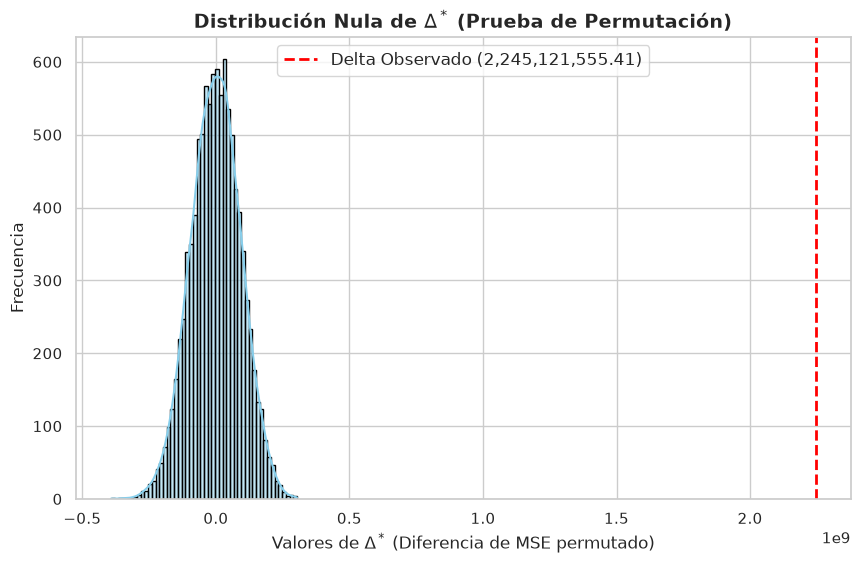

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

sns.histplot(delta_estrellas, bins=50, kde=True, color='skyblue', edgecolor='black')

delta_observado = mse_lineal - mse_no_lineal

plt.axvline(delta_observado, color='red', linestyle='--', linewidth=2, 
            label=f'Delta Observado ({delta_observado:,.2f})')

plt.title('Distribución Nula de $\Delta^*$ (Prueba de Permutación)', fontsize=14, fontweight='bold')
plt.xlabel('Valores de $\Delta^*$ (Diferencia de MSE permutado)', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.legend(fontsize=12)

plt.show()

A partir del grafico nos damos cuenta que la distribucion nula parece estar centrada en 0, por que al hacer premutaciones estamos simulacion que pasaria si ambos modelos tuvieran el mismo desempeño. Pero nuestro delta observado por la comparacion del modelo lineal con el modelo no lineal es mucho mas grande mostrando la diferencia real entre los modelos.

## Calculamos el p-valor para MSEDelta

In [37]:
# Calcular el Delta observado
delta_obs = mse_lineal - mse_no_lineal
B = len(delta_estrellas) # Número de permutaciones (10000)

# Contar cuántos valores absolutos de Delta* son mayores o iguales al valor absoluto del Delta observado
conteo = np.sum(np.abs(delta_estrellas) >= np.abs(delta_obs))

# Aplicar la fórmula de la guía para el p-valor
p_valor = (1 + conteo) / B

print(f"Número de permutaciones extremas encontradas: {conteo}")
print(f"P-valor calculado: {p_valor}")

Número de permutaciones extremas encontradas: 0
P-valor calculado: 0.0001


## Decision con alpha = 0.05 

H0: No hay diferencia real en el rendimiento del modelo lineal con el modelo no lineal.

MSEDelta = 0

H1: Existe una diferencia real en el rendimiento del modelo lineal con el modelo no lineal.

MSEDelta != 0

Rechazar H0

0.05 > p (0.0001)


Con un alpha de 0.05 existe suficiente evidencia para rechazar H0, por lo tanto se puede esperar que el rendimiento entre el modelo lineal y el no lineal sea diferente.

# Conclusión estadistica

Se realizon una prueba de permutación bilateral utilizando 10,000 premutaciones para comparar el desempeño de un modelo de regresión lineal con un modelo de regresión no lineal (Random forest), utilizando el error cuadratico medio calculado sobre el mismo conjunto de prueba. Para esta prueba se establecieron las siguientes hipótesis

H0: No hay diferencia real en el rendimiento del modelo lineal con el modelo no lineal.

MSEDelta = 0

H1: Existe una diferencia real en el rendimiento del modelo lineal con el modelo no lineal.

MSEDelta != 0

El estadistico de prueba calculado, se calculo mediante la observacion de la diferencia de los errores cuadrados medios MSEDelta = MSEA - MSEB donde MSEA corresponde al modelo lineal y MSEB al modelo Random Forest. Para consitruir la distribución nula, se intercambiaron aleatoriamente los errores cuadrados de ambos modelos para cada observación de las 10,000 premutaciones independientes para calcular los valoes MSEDelta simulados. Al realizar esta prueba se obtuvo un p valor de 0.0001, el cual indica que ninguna de las 10,000 premutaciones aleatoria alcanzo o supero en magnitud a la diferencia observada entre los modelos. 

Con un nivel de significancia de 0.05 existe suficiente evidencia para rechazar H0, ya que el p-valor es menor que 0.05. Por lo tanto, existe suficiente evidencia estadistica para concluir que hay una diferencia entre el rendimiento entre el modelo lineal y no lineal (Random Forest).